# M17 · Jacobienne et règle de la chaîne — solutions (notebook exécuté)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cemah2/workbookMaths/blob/main/chapitres/m17_jacobienne/05_solutions.ipynb)

Les réponses des exercices, exécutées. Les démarches détaillées (le *pourquoi*, les erreurs fréquentes, les variantes) sont dans `05_solutions.md`. Les cellules marquées `answer` enregistrent les réponses vérifiées par `wbm.check` (`tools/build_answers.py`).

| Partie | ID | Titre | Type | ★ | ⏱️ |
|---|---|---|---|---|---|
| 0 | M17.1 à M17.7, M17.11 | Les exercices papier (vérification) | ✏️ | | |
| A | M17.14 | La jacobienne par différences centrées, colonne par colonne · `numerical_jacobian` | 🔨 | ★★ | 20 |
|  | M17.15 | Une jacobienne diagonale avec une seule paire d'évaluations · `diagonal_jacobian` | 🔨 | ★ | 15 |
|  | M17.16 | Un produit jacobienne-vecteur sans former la jacobienne · `jacobian_vector_product` | 🔨 | ★ | 15 |
| B | M17.17 | `sympy.Matrix.jacobian` et `scipy.differentiate.jacobian` contre ta jacobienne numérique | 📦 | ★ | 15 |
|  | M17.18 | Prédire la forme et les zéros de la jacobienne d'une composée, puis vérifier | 🔮 | ★ | 10 |
|  | M17.19 | Une longue composition : une dérivée qui s'éteint ou explose selon la pente au point fixe | 🔬 | ★★ | 20 |
|  | M17.20 | Une grille du plan déformée par une application non linéaire, et par son approximation linéaire | 🎨 | ★ | 20 |
| C | M17.21 | Chasse à l'erreur : une jacobienne transposée, un produit dans le mauvais ordre, une jacobienne évaluée au mauvais point | 🐛 | ★ | 15 |
|  | M17.22 | Un test de propriété : J_{g∘f} = J_g J_f sur des applications tirées au hasard | 🛠️ | ★ | 15 |
|  | M17.23 | Défi : la jacobienne de l'inversion X ↦ X⁻¹, vue comme une application de ℝ^{n²} dans ℝ^{n²} | 🏆 | ★★★ | 25 |

In [1]:
# ⚙️ SETUP: run this cell first (on Colab or on your computer)
FAST_MODE = True  # True = quick version (a few seconds per cell); False = bigger experiments
SEED = 42

import os
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/cemah2/workbookMaths.git"
DRIVE_DIR = Path("/content/drive/MyDrive/workbookMaths")

try:
    import google.colab  # noqa: F401  (this module only exists on Colab)
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    from google.colab import drive

    drive.mount("/content/drive")
    subprocess.run(["git", "config", "--global", "--add", "safe.directory", str(DRIVE_DIR)])
    if not (DRIVE_DIR / ".git").exists():
        subprocess.run(["git", "clone", REPO_URL, str(DRIVE_DIR)], check=True)
    else:
        # Get the new chapters. Your own work only lives in mon_travail/, which Claude never
        # touches, so "rebase + autostash" keeps it safe (even with local commits).
        identity = subprocess.run(["git", "-C", str(DRIVE_DIR), "config", "user.email"],
                                  capture_output=True).returncode == 0
        who = [] if identity else ["-c", "user.name=Workbook", "-c", "user.email=workbook@localhost"]
        pull = subprocess.run(["git", *who, "-C", str(DRIVE_DIR), "pull", "--rebase", "--autostash"],
                              capture_output=True, text=True)
        conflicts = subprocess.run(["git", "-C", str(DRIVE_DIR), "diff", "--name-only", "--diff-filter=U"],
                                   capture_output=True, text=True).stdout.split()
        if conflicts:  # a file changed outside mon_travail/ AND by Claude: git leaves conflict markers in it
            print("⚠️ Tes modifications de " + ", ".join(conflicts) + " (hors de mon_travail/) entrent en conflit "
                  "avec la nouvelle version ; elles sont gardées dans `git stash`. Pour reprendre la version du "
                  "dépôt : git restore --source=HEAD --staged --worktree <fichier> (00_setup/COLAB.md, « Problèmes "
                  "fréquents »).")
        elif pull.returncode != 0:
            print("⚠️ git pull a échoué (voir 00_setup/COLAB.md, « Problèmes fréquents ») :\n" + pull.stderr)
    ROOT = DRIVE_DIR
else:
    ROOT = Path(os.environ.get("WBM_ROOT", Path.cwd())).resolve()
    while not (ROOT / "src" / "wbm").exists() and ROOT != ROOT.parent:
        ROOT = ROOT.parent
    if not (ROOT / "src" / "wbm").exists():
        raise FileNotFoundError("Dépôt introuvable : ouvre ce notebook depuis le dossier de workbookMaths.")

os.environ["WBM_ROOT"] = str(ROOT)
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

import wbm  # noqa: E402

cfg = wbm.setup(seed=SEED, fast=FAST_MODE)
FAST_MODE = cfg.fast
mymath = wbm.load_mymath("ref")  # reference implementation

🧪 workbookMaths : environnement
   Plateforme : Local (Linux x86_64, 2 CPU)
   Python 3.13.18 | numpy 2.1.3 | scipy 1.16.3 | sympy 1.14.0 | matplotlib 3.10.0 | pandas 2.2.3 | scikit-learn 1.6.1
   Graine : 42 | FAST_MODE : True


## Objectifs et rappel express

- Vérifier tes calculs papier (partie 0) : la jacobienne des coordonnées polaires et l'approximation linéaire, une jacobienne diagonale, une composée de trois applications, la normalisation $\mathbf{x}/\lVert\mathbf{x}\rVert$, un gradient dans les deux conventions, des dérivées à gauche et à droite et une composée de sept copies, deux lois de Boltzmann.
- Écrire les trois fonctions de `mymath/jacobian.py` et les tester.
- Comparer ta jacobienne à celles de SymPy et de SciPy, prédire la jacobienne d'une composée, suivre la dérivée d'une longue itération, voir une approximation linéaire, corriger des erreurs classiques, écrire un test de propriété, et relever un défi : la jacobienne de l'inversion des matrices.

**Rappel express.** Pour $\mathbf{f} : \mathbb{R}^n \to \mathbb{R}^m$, $\mathbf{J}_{\mathbf{f}}$ a la forme $(m, n)$, $J_{ij} = \frac{\partial f_i}{\partial x_j}$ : une ligne par sortie, une colonne par entrée. $\mathbf{f}(\mathbf{x} + \mathbf{h}) \approx \mathbf{f}(\mathbf{x}) + \mathbf{J}\mathbf{h}$, et $\lvert\det\mathbf{J}\rvert$ multiplie les aires. Coordonnée par coordonnée : $\mathbf{J} = \mathrm{diag}(g'(x_1), \ldots, g'(x_n))$, $\mathbf{J}\mathbf{v} = g'(\mathbf{x}) \odot \mathbf{v}$. $\mathbf{J}_{\mathbf{g} \circ \mathbf{f}}(\mathbf{x}) = \mathbf{J}_{\mathbf{g}}(\mathbf{f}(\mathbf{x}))\,\mathbf{J}_{\mathbf{f}}(\mathbf{x})$ : la dernière à gauche, au point intermédiaire. $\nabla_{\mathbf{x}}(L \circ \mathbf{f}) = \nabla_{\mathbf{y}}L\,\mathbf{J}_{\mathbf{f}}$ en ligne, $\mathbf{J}_{\mathbf{f}}^\top\nabla_{\mathbf{y}}L$ de la forme de la variable. $\mathbf{J}\mathbf{v} \approx \frac{\mathbf{f}(\mathbf{x} + h\mathbf{v}) - \mathbf{f}(\mathbf{x} - h\mathbf{v})}{2h}$ : deux évaluations. Une itération : $\frac{\mathrm{d}x_L}{\mathrm{d}x_0} = \prod_k\varphi'(x_k)$. Boltzmann : $p_i = \frac{e^{-E_i/T}}{\sum_je^{-E_j/T}}$.

## Partie 0 · Vérifier tes exercices papier (✏️ M17.1 à M17.7, M17.11)

Fais d'abord les exercices de `02_exercices.md` **sur papier**, dans ta copie de `06_mes_reponses.md`. Reporte ensuite chaque réponse ici : **la valeur** que tu as trouvée, sous la forme indiquée en commentaire, jamais le calcul qui y mène :
- un entier, ou un nombre avec un point décimal, `-1.25`, arrondi comme le demande la question ;
- une liste `[0.2, -1]` ;
- une matrice comme la liste de ses **lignes** : `[[1, 0], [-2, 3]]` ; un nombre décimal s'y écrit avec un point, `[[0.5, 1], [0, 2]]`, ou comme un calcul, `[[1/2, 1], [0, 2]]` ;
- une fraction irréductible entre guillemets, `"3/7"`, quand la question le dit.

Les réponses pas encore remplies affichent ⏳.

In [2]:
# Part 0: the answers are computed exactly (SymPy, fractions) from the statements
import math
from fractions import Fraction

import sympy

R = sympy.Rational


def rows(M):
    """A SymPy matrix as the list of its rows (Python ints, floats for the other numbers)."""
    return [[int(v) if v.is_Integer else float(v) for v in M.row(i)] for i in range(M.rows)]


def flat(values):
    """SymPy numbers (a row, a column, a list) as a flat list (Python ints, floats for the other numbers)."""
    return [int(v) if sympy.sympify(v).is_Integer else float(v) for v in values]


R_1, T_1 = sympy.Integer(4), sympy.pi / 6                                                        # M17.1
F_1 = sympy.Matrix([R_1 * sympy.cos(T_1), R_1 * sympy.sin(T_1)])
J_1 = sympy.Matrix([[sympy.cos(T_1), -R_1 * sympy.sin(T_1)], [sympy.sin(T_1), R_1 * sympy.cos(T_1)]])
J_NO_R_1 = sympy.Matrix([[sympy.cos(T_1), -sympy.sin(T_1)], [sympy.sin(T_1), sympy.cos(T_1)]])
H_1 = sympy.Matrix([R(1, 10), R(1, 20)])                       # the move (dr, dθ) of d) and e)
LINEAR_1 = F_1 + J_1 * H_1
EXACT_1 = sympy.Matrix([R(41, 10) * sympy.cos(T_1 + R(1, 20)), R(41, 10) * sympy.sin(T_1 + R(1, 20))])
DEGREES_1 = [4 * math.cos(math.radians(math.pi / 6)), 4 * math.sin(math.radians(math.pi / 6))]   # a calculator in °
THIRTY_1 = [4 * math.cos(30), 4 * math.sin(30)]                # 30 read as radians
t_ = sympy.Symbol("t")                                                                           # M17.2
G_2 = sympy.log(1 + t_ ** 2)
X_2, V_2 = [1, -2, 0, 3], [2, 1, -5, R(1, 2)]
DG_2 = [sympy.diff(G_2, t_).subs(t_, x) for x in X_2]          # g′(t) = 2t / (1 + t²)
G_VALUES_2 = [G_2.subs(t_, x) for x in X_2]
DXG_2 = [sympy.diff(t_ * G_2, t_).subs(t_, x) for x in X_2]    # (t g(t))′ = g(t) + t g′(t)
x_, y_, u_, v_, w_, a_, b_ = sympy.symbols("x y u v w a b")                                       # M17.3
F1_3 = sympy.Matrix([x_ + y_, x_ * y_, x_ - y_])
F2_3 = sympy.Matrix([u_ * v_, v_ + w_ ** 2])
F3_3 = sympy.Matrix([a_ ** 2 - 3 * b_])
P_3 = {x_: 1, y_: 2}
Y1_3 = F1_3.subs(P_3)                                          # f1(1, 2)
Q_3 = dict(zip((u_, v_, w_), Y1_3))
Y2_3 = F2_3.subs(Q_3)                                          # f2(f1(1, 2))
J1_3 = F1_3.jacobian([x_, y_]).subs(P_3)
J2_3 = F2_3.jacobian([u_, v_, w_]).subs(Q_3)
J2_SWAP_3 = sympy.Matrix([[u_, v_, 0], [0, 1, 2 * w_]]).subs(Q_3)   # the two partial derivatives of uv swapped
J2_SIGN_3 = F2_3.jacobian([u_, v_, w_]).subs({u_: Y1_3[0], v_: Y1_3[1], w_: -Y1_3[2]})
J3_JAC_3 = F3_3.jacobian([a_, b_])
J3_3 = J3_JAC_3.subs(dict(zip((a_, b_), Y2_3)))
J3_EARLY_3 = J3_JAC_3.subs({a_: Y1_3[0], b_: Y1_3[1]})       # at the first two coordinates of f1(1, 2)
J3_AT_X_3 = J3_JAC_3.subs({a_: 1, b_: 2})                    # at the starting point
COST_3 = [J3_3.rows * J3_3.cols * J2_3.cols + J3_3.rows * J2_3.cols * J1_3.cols,     # (J3 J2) J1
          J2_3.rows * J2_3.cols * J1_3.cols + J3_3.rows * J3_3.cols * J1_3.cols]     # J3 (J2 J1)
X_4, V_4 = sympy.Matrix([3, 0, 4]), sympy.Matrix([0, 2, 1])                                      # M17.4
NORM_4 = X_4.norm()
U_4 = X_4 / NORM_4
P_4 = sympy.eye(3) - U_4 * U_4.T                               # the orthogonal projection on the plane orthogonal to u
JN_4 = P_4 / NORM_4
x1_, x2_, y1_, y2_, y3_ = sympy.symbols("x1 x2 y1 y2 y3")                                        # M17.5
F_5 = sympy.Matrix([x1_ - x2_, x1_ * x2_, x2_ ** 2])
L_5 = y1_ ** 2 + 3 * y2_ - y3_
P_5 = {x1_: 2, x2_: -1}
Y_5 = F_5.subs(P_5)
GRAD_L_5 = sympy.Matrix([[sympy.diff(L_5, y) for y in (y1_, y2_, y3_)]])     # a row, as in MML
GL_5 = GRAD_L_5.subs(dict(zip((y1_, y2_, y3_), Y_5)))
GL_AT_X_5 = GRAD_L_5.subs({y1_: 2, y2_: Y_5[1], y3_: Y_5[2]})             # y1 read as x1 = 2
JF_5 = F_5.jacobian([x1_, x2_]).subs(P_5)
SLOPES_6 = (Fraction(15, 100), Fraction(25, 100), Fraction(1, 10))                               # M17.6


def bill_6(x):
    """c(x), the bill in € for x kWh, in exact fractions."""
    x = Fraction(x)
    if x <= 100:
        return SLOPES_6[0] * x
    if x <= 300:
        return 15 + SLOPES_6[1] * (x - 100)
    return 65 + SLOPES_6[2] * (x - 300)


XS_6 = [Fraction(1)]                                           # x_0 = 1, then x_{k+1} = 1 / (1 + x_k), up to x_8
for _ in range(8):
    XS_6.append(1 / (1 + XS_6[-1]))
DER_6 = math.prod(Fraction(-1) / (1 + XS_6[k]) ** 2 for k in range(7))      # the product of g′(x_k), k = 0 … 6
DER_NO_SQUARE_6 = math.prod(Fraction(-1) / (1 + XS_6[k]) for k in range(7))
E_7 = (0, 1, 2, 4)                                                                               # M17.7


def populations_7(T):
    """The Boltzmann populations of the levels E_7 at the temperature T (exact SymPy numbers)."""
    weights = [sympy.exp(-sympy.Integer(E) / T) for E in E_7]
    return [w / sum(weights) for w in weights]


P1_7 = populations_7(sympy.Integer(1))
MEAN_7 = sum(E * p for E, p in zip(E_7, P1_7))
T_SYMBOL_7 = sympy.Symbol("T", positive=True)
T_HALF_7 = sympy.nsolve(sum(sympy.exp(-sympy.Integer(E) / T_SYMBOL_7) for E in E_7[1:]) - 1, T_SYMBOL_7, 1.8,
                        prec=30)                               # p_0 = 1/2 ⇔ e^(−1/T) + e^(−2/T) + e^(−4/T) = 1
LENGTHS_11 = (41, 38, 45, 39, 40)                                                                # M17.11: A to E


def tours_11(T):
    """The Boltzmann probabilities of the five tours at the temperature T (exact SymPy numbers)."""
    weights = [sympy.exp(-(sympy.Integer(length) - 38) / sympy.sympify(T)) for length in LENGTHS_11]
    return [w / sum(weights) for w in weights]

**Ex M17.1 — La jacobienne des coordonnées polaires, son déterminant, et l'approximation linéaire près d'un point**

In [3]:
wbm.record("M17.1a", flat(F_1), decimals=4, mistakes={"les angles sont en radians : ta calculatrice est-elle réglée en degrés ?": DEGREES_1,
                     "θ = π/6 radian : ne remplace pas π/6 par 30 dans un cosinus qui attend des radians": THIRTY_1})
wbm.record("M17.1b", rows(J_1), decimals=4, mistakes={"une ligne par SORTIE et une colonne par entrée : la ligne 1 est le gradient de r cos θ": rows(J_1.T),
                     "dérive r sin θ par rapport à θ : le facteur r reste": rows(J_NO_R_1)})
wbm.record("M17.1c", int(sympy.simplify(J_1.det())), mistakes={"le facteur r de la deuxième colonne reste dans le déterminant": 1,
                     "det = ad − bc : attention au signe du produit des coefficients hors de la diagonale": -4})
wbm.record("M17.1d", flat(LINEAR_1), decimals=4, mistakes={"J h, avec h = (0,1 ; 0,05) en colonne : la jacobienne, pas sa transposée":
                         flat(F_1 + J_1.T * H_1),
                     "l'approximation linéaire est f(a) + J h : n'oublie pas f(a)": flat(J_1 * H_1)})
wbm.record("M17.1e", flat(EXACT_1), decimals=4)
wbm.record("M17.1f", float((LINEAR_1 - EXACT_1).norm()), decimals=4)
wbm.record("M17.1g", float(abs(sympy.simplify(J_1.det())) * R(1, 100) * R(2, 100)), decimals=4, mistakes={"les aires sont multipliées par |det J| : l'aire du petit rectangle ne suffit pas":
                         float(R(1, 100) * R(2, 100))})

WBM_ANSWER {"decimals": 4, "element_coarse": [["c0ac8ab0b3bfbef7f5248cd2723863ce547c98b9435937102621d85fc731e631"], ["38f61d2f0da6bede1eb37bc53fd0ace979c55543ff025d9c1e8c798e8cc73b83"]], "element_coarse_any": [["f0c8b3648cae69d488bdd040c009d4e004cdb8c44480e9ddd5cd51f007152102", "33b5ebcf9cd67e2de655d0c21a765ec7235f9c02c94c9895414cf6fffaecc8a7", "5b8dde6d8f1910e77b4eb9f0ab6215f7f1cef0604b2403b3fb1f3122ce066e36"], ["d63c47bdd82ecee8c0a3d8afcd868dbf773b72275fbd6c1b10aa7e901723561c", "8a9d1bd20f249ee28b6e9653e56835d3758ef3bd9374304e3f88181fb18e95ad", "e8aaaa6a43a225b816dfc2d6a7ba951227dc54a273328d7b35e0e0fe77feeec0"]], "element_hashes": ["d013647b2222a4b844d9400a7f5cd29786fe93e517cdbda43cd576329168833d", "8d3a172254f870bdab4a751c0e49ea3f7496a202135fd9219063f10b6c2f8b2e"], "hash": "b2b8de69e6f66e5fca1314c9aaf3165978230123059fedd1097dc9afbcd14c3d", "id": "M17.1a", "kind": "array", "mistakes": {"4888025e8d5683a86fbfa14b4a5493a80b0ccfa94743ba3997d70f3ea6027866": "θ = π/6 radian : ne remplace p

**Ex M17.2 — Une fonction appliquée coordonnée par coordonnée : la jacobienne diagonale, et son produit par un vecteur**

In [4]:
wbm.record("M17.2a", flat(DG_2), decimals=4, mistakes={"la diagonale porte les DÉRIVÉES g′(xᵢ), pas les valeurs g(xᵢ)": flat(G_VALUES_2)})
wbm.record("M17.2b", flat([d * v for d, v in zip(DG_2, V_2)]), decimals=4, mistakes={"J v est un vecteur, une coordonnée par sortie : le produit case par case g′(x) ⊙ v, pas un produit scalaire": [float(sum(d * v for d, v in zip(DG_2, V_2)))]})
wbm.record("M17.2c", sum(1 for i in range(4) for j in range(4) if i != j or DG_2[i] == 0), mistakes={"compte aussi les zéros de la diagonale : calcule chaque g′(xᵢ)": 12})
wbm.record("M17.2d", 1000 ** 2 - 1000, mistakes={"hors de la diagonale : n² coefficients en tout, moins les n de la diagonale": 1000 ** 2,
                     "hors de la diagonale : les deux triangles, au-dessus ET au-dessous": (1000 ** 2 - 1000) // 2})
wbm.record("M17.2e", [2, 2 * 1000], mistakes={"pour la diagonale, toutes les coordonnées bougent ensemble : une seule paire d'évaluations":
                         [2 * 1000, 2 * 1000],
                     "des différences CENTRÉES : deux évaluations par colonne, en x + h e_j et en x − h e_j": [2, 1000],
                     "l'ordre demandé : la diagonale d'abord, puis la jacobienne entière": [2 * 1000, 2]})
wbm.record("M17.2f", flat(DXG_2), decimals=3, mistakes={"t g(t) est un produit : sa dérivée a deux termes, g(t) + t g′(t)":
                         flat([x * d for x, d in zip(X_2, DG_2)]),
                     "règle du produit : (t g(t))′ = g(t) + t g′(t), le second terme compte aussi": flat(G_VALUES_2)})

WBM_ANSWER {"decimals": 4, "element_coarse": [["4b69cb6d8052f3ce30ad3badc9a8e381ada98769bf37362048591cd66f9dbab3"], ["997455c7cd454f72854520222296827ba2986aa50dc77688435d4235db660fa2"], ["701ee71e4aa18179739853f87a0c31af424294022c8f2174e24f713fbec95d0b"], ["c8c2e4a5b432ed2e93a486b535840f230b30246eddcb04eeb3518ea84bb5c1f9"]], "element_coarse_any": [["c8e49c1115eda4e61061356cb1d394bf8f987205e9e2413615c4f15bf8b967ee", "384c27fc3cb4fb075b42e4edd68f552f2bbf1fe3e394551f1f77aa85e674f75f", "46e16edcb223cc9cdb5dcb33163fc36fd4d83b870a2786b549a5a11a2a373371"], ["543ef6b74e8c441455985758a9049922a9e0c52f73aed0e48c52c6b7ead87401", "e8fd5a3e55ccd414cce6492f69106c2c2897ba8309ee074df8bd5394d81e5526", "fefcbb5b1598a8dc3cb7c695aca03bac39c837ba0534e8ea36c769e5422929e3"], [], ["8d6023c69606f851cae567a8b0a38fc6d6c3b9a1937b84bdc2c9b1852ac077f2", "b4165fbbbf48321d371ebf86d84e8f2ad8739cde0435a6fc8d598988ea9b721d", "0cb46fc3f894a6c6de87f92ca756fefe0fafeaa37e520f409b181cb1075e895f"]], "element_hashes": ["242ef21

**Ex M17.3 — Dériver une composée de trois applications par le produit de leurs jacobiennes**

In [5]:
wbm.record("M17.3a", flat(Y1_3))
wbm.record("M17.3b", rows(J1_3), mistakes={"une ligne par SORTIE et une colonne par entrée : f₁ a 3 sorties et 2 entrées, sa jacobienne 3 lignes et 2 colonnes": rows(J1_3.T)})
wbm.record("M17.3c", rows(J2_3), mistakes={"une ligne par SORTIE et une colonne par entrée : f₂ a 2 sorties et 3 entrées, sa jacobienne 2 lignes et 3 colonnes": rows(J2_3.T),
                     "∂(uv)/∂u = v et ∂(uv)/∂v = u": rows(J2_SWAP_3),
                     "J_f₂ s'évalue en f₁(1, 2) : w = x − y, attention au signe": rows(J2_SIGN_3)})
wbm.record("M17.3d", rows(J3_3), mistakes={"J_f₃ s'évalue au point où l'on applique f₃, f₂(f₁(1, 2)), pas en les deux premières coordonnées de f₁(1, 2)": rows(J3_EARLY_3),
                     "J_f₃ s'évalue au point où l'on applique f₃, f₂(f₁(1, 2)), pas au point de départ (1, 2)":
                         rows(J3_AT_X_3)})
wbm.record("M17.3e", flat(J3_3 * J2_3 * J1_3), mistakes={"J_f₃ s'évalue en f₂(f₁(1, 2)) : revois d)": flat(J3_EARLY_3 * J2_3 * J1_3),
                     "J_f₃ s'évalue en f₂(f₁(1, 2)), pas en (1, 2) : revois d)": flat(J3_AT_X_3 * J2_3 * J1_3)})
wbm.record("M17.3f", COST_3, mistakes={"l'ordre demandé : (J_f₃ J_f₂) J_f₁ d'abord, puis J_f₃ (J_f₂ J_f₁)": COST_3[::-1]})

WBM_ANSWER {"decimals": 0, "element_hashes": ["f732f2b0d4f8ac4c9bf42814276e6bccb8da2e9cb93a7fc7174cc3bccf3a5b45", "f2f943f3e301eba5e83a8908e785600a891c92d5215d48e1aa972e92d869a922", "ea017c2c0ab1abacaf2aad1b711b861f7fc8349ca3d1af2faf5309dc303e5a14"], "hash": "fcef9d0a0068e557f5260e81e6980d270b7cce05df0b23cb280b8e5bf642fad0", "id": "M17.3a", "integer": true, "kind": "array", "shape": [3]}
📝 Ex M17.3a : réponse enregistrée (array, 0 décimale).
WBM_ANSWER {"decimals": 0, "element_hashes": ["8f4e97debd28d20933fff2e4d10e57e536cacd312cf75734a5573a07526fef6f", "4858b1d46095d99a3df781bd55629a76b9dac0e499de18dbbcd02b68c54d26c9", "6e0db96f8e465219a03007f0e131ab1f239a786f761019734ded98effe51ddce", "bdaa8e641a65bdd3359a4b73b57bfe8cb7eed445b8b6973fb0eefad875498303", "da5b8444842de80db76e322d2d4c028d0d8ae02138dd2c8353fab2cd69c14b9d", "2ef5cbd02113967a6598e4bf7e590590e9214542dce452e6395251d42c03c881"], "hash": "aacab982c49ea2365644a0f5a3dce225c4a97261c0e72ed93379549c5ddc3214", "id": "M17.3b", "intege

**Ex M17.4 — La normalisation x/‖x‖ : sa jacobienne (I − uuᵀ)/‖x‖, et la direction qu'elle écrase**

In [6]:
wbm.record("M17.4a", flat([NORM_4, *U_4]), decimals=4, mistakes={"‖x‖ est la RACINE de la somme des carrés": flat([NORM_4 ** 2, *(X_4 / NORM_4 ** 2)])})
wbm.record("M17.4b", rows(JN_4), decimals=4, mistakes={"divise la projection I − uuᵀ par ‖x‖": rows(P_4),
                     "uuᵀ est une matrice (une colonne fois une ligne), pas le nombre uᵀu = 1": rows(sympy.zeros(3, 3))})
wbm.record("M17.4c", flat(JN_4 * X_4), decimals=4, mistakes={"J x n'est pas u : calcule (x − (u · x) u) / ‖x‖": flat(U_4)})
wbm.record("M17.4d", flat((V_4 - U_4.dot(V_4) * U_4) / NORM_4), decimals=4, mistakes={"divise par ‖x‖ = 5": flat(V_4 - U_4.dot(V_4) * U_4)})
wbm.record("M17.4e", JN_4.rank(), mistakes={"J envoie x lui-même sur 0 (revois c) : une direction est écrasée": 3})
wbm.record("M17.4f", flat(sorted(JN_4.eigenvals(multiple=True))), decimals=4, mistakes={"ce sont les valeurs propres de la projection I − uuᵀ : divise-les par ‖x‖":
                         flat(sorted(P_4.eigenvals(multiple=True)))})

WBM_ANSWER {"decimals": 4, "element_coarse": [["95381aa05156e97f17e0115ff0b41c088efe1de7703bc6ef9162005f6f216e85"], ["f9238cfaa8263d698930f1326b5ed049a7756115003a44c8afa77a64b205c765"], ["0c61fa04e8903f5f8de3e506ff71cc1b97b45bb3d783290eeba0f662c0cc3cc8"], ["7bd3e5b846d0dfdb08dff72759186ef1b6bb28cb1acde492d3ee1eed1a0fe786"]], "element_coarse_any": [["ee6028fa27f6e772bd9f74e60fa7a1a28f53c012a975341d51ddebdbaa8e6456", "69793e4ebc1c6455ec9fa3729159fbcdaec042668c479d657c20ddea2017232f", "4421474d8246391c4091ec429072543db8484de5c46881cd5a75ce7ca97353b5"], ["343476ddb502c88e00a86e05f28805110e4c5921fbd4fffffe18336a54acd0de", "cb1640a7fac3aae0663eb67d3b38738b5933ed85a0107fcf5e5a2cf674cb7f63", "1318440a36d8987cfacec96a19055a0e7e49a5f4595c8d6f691da0abf0f23087"], [], ["383e8c7d288bb15d126c147a1406e21c3f5984a8008c487e55a23c7f50f9217f", "3cf997ea0f91cc3cbbd3cc1b59366c1087a070c39dc1d51451021670af37b915", "f0fdeceb6b39ffdbd567010054e439f95ba9155dd226321b3ac1d67002373f0c"]], "element_hashes": ["9930482

**Ex M17.5 — Le gradient d'une fonction scalaire d'une composée, dans les deux conventions : J_fᵀ ∇L**

In [7]:
wbm.record("M17.5a", flat(Y_5))
wbm.record("M17.5b", flat(GL_5), mistakes={"∇L s'évalue au point intermédiaire y = f(x) : y₁ = x₁ − x₂": flat(GL_AT_X_5)})
wbm.record("M17.5c", rows(JF_5), mistakes={"une ligne par SORTIE et une colonne par entrée : f a 3 sorties et 2 entrées, sa jacobienne 3 lignes et 2 colonnes": rows(JF_5.T)})
wbm.record("M17.5d", flat(GL_5 * JF_5), mistakes={"∇L s'évalue au point intermédiaire y = f(x) : revois b)": flat(GL_AT_X_5 * JF_5)})
wbm.record("M17.5e", list(JF_5.T.shape), mistakes={"J_f a la forme (3, 2) : sa transposée échange lignes et colonnes": list(JF_5.shape)})
wbm.record("M17.5f", float((GL_5 * JF_5 * sympy.Matrix([1, 1]))[0]), decimals=4, mistakes={"la question demande la dérivée de t ↦ (L∘f)(x + t(1, 1)), sans normaliser la direction": float((GL_5 * JF_5 * sympy.Matrix([1, 1]))[0] / sympy.sqrt(2))})

WBM_ANSWER {"decimals": 0, "element_hashes": ["65cca5c5e7483fad7e8bf53d8993ef16e60891b055cb0ad7d13936a734b51d3a", "74b19a9cb0d92e64848e5f7bd22261ab30f91d98ebf452241441ee971df5cae1", "023432284f82f880c8a381b75c30de36a5397878b0d5b85f4e8992eece324225"], "hash": "8dc12c78f2d05510dd1e6f1728080d741eba0be03c36328d038a6d77afee16c6", "id": "M17.5a", "integer": true, "kind": "array", "shape": [3]}
📝 Ex M17.5a : réponse enregistrée (array, 0 décimale).
WBM_ANSWER {"decimals": 0, "element_hashes": ["b98a5acf5b9d158f64de6f1a1b9977ae8103f306682f9e112327e200dab43dcc", "73ce11327fde8e605d93c9a7799d7cf900096e7a1cbcea80103157e9c2e163a6", "36ebfdb62a40383556c530fae8cd875cd02b7bafd4f068e72fd44368d499b9af"], "hash": "1866cf5bf2d5aefdc18ce86ba7b8e7b3898362a4bc73b1cd3a36b6bbf5d2692a", "id": "M17.5b", "integer": true, "kind": "array", "mistakes": {"0463651876baf985bfcaf0df9171efd545e37390927d9a9b5128a9eeb894595d": "∇L s'évalue au point intermédiaire y = f(x) : y₁ = x₁ − x₂"}, "shape": [3]}
📝 Ex M17.5b : répon

**Ex M17.6 — Dérivées à gauche et à droite d'une fonction définie par morceaux, et la dérivée d'une composée de sept copies d'une fonction lisse**

In [8]:
wbm.record("M17.6a", int(bill_6(320)), mistakes={"au-delà de 300 kWh, c'est le troisième morceau qui s'applique : la remise, à 0,1 € le kWh":
                         int(15 + SLOPES_6[1] * (320 - 100)),
                     "au-delà de 300 kWh, le kWh coûte 0,1 €, pas le prix de la première tranche":
                         int(65 + SLOPES_6[0] * (320 - 300)),
                     "chaque tranche a son prix : 65 € pour les 300 premiers kWh, puis le prix de la troisième tranche":
                         int(SLOPES_6[2] * 320)})
wbm.record("M17.6b", flat(SLOPES_6[:2]), decimals=4, mistakes={"à gauche de 100, la pente du morceau de gauche ; à droite, celle du morceau de droite": flat(SLOPES_6[1::-1])})
wbm.record("M17.6c", flat(SLOPES_6[1:]), decimals=4, mistakes={"à gauche de 300, la pente du morceau de gauche ; à droite, celle de la remise":
                         flat(SLOPES_6[:0:-1])})
wbm.record("M17.6d", flat([-SLOPES_6[1], SLOPES_6[1]]), decimals=4, mistakes={"à gauche du point où c(x) = 40, c(x) − 40 est négatif : |c(x) − 40| = 40 − c(x)":
                         flat([SLOPES_6[1], SLOPES_6[1]])})
wbm.record("M17.6e", str(XS_6[7]), kind="fraction", simplified=True,
           mistakes={"x₇ : sept applications de g à partir de x₀ = 1, et il en manque une": str(XS_6[6]),
                     "x₇ : sept applications de g à partir de x₀ = 1, et il y en a une de trop": str(XS_6[8])})
wbm.record("M17.6f", str(DER_6), kind="fraction", simplified=True,
           mistakes={"g′(x) = −1/(1 + x)² est négative : compte les signes des sept facteurs": str(-DER_6),
                     "chaque g′ s'évalue en son point de la trajectoire, x₀, x₁, …, x₆, pas toujours en x₀ = 1":
                         str(Fraction(-1, 4) ** 7),
                     "g′(x) = −1/(1 + x)² : n'oublie pas le carré": str(DER_NO_SQUARE_6)})
wbm.record("M17.6g", float((3 - sympy.sqrt(5)) / 2), decimals=3, mistakes={"c'est x* = 1/(1 + x*) : |g′(x*)| = 1/(1 + x*)² en est le carré":
                         float((sympy.sqrt(5) - 1) / 2)})

WBM_ANSWER {"hash": "6331560fa311b6168b07a2f3f9b1b6bdb87862f35f60b5a7f0434e802ab81694", "id": "M17.6a", "kind": "int", "magnitude": 1, "mistakes": {"0207fbe34a64c3cec254a3f9e84ca1f91f7e7b21f5da1cb44acaa2ba523cb1b3": "au-delà de 300 kWh, le kWh coûte 0,1 €, pas le prix de la première tranche", "6130f1d583c7d874f2370f7059f9f00de34bfc67fe29307082e4842063fff879": "au-delà de 300 kWh, c'est le troisième morceau qui s'applique : la remise, à 0,1 € le kWh", "a5eba53a9acb57ec6c795ff3cc463bb2e10a1990b16846879c73b7ad42edcec1": "chaque tranche a son prix : 65 € pour les 300 premiers kWh, puis le prix de la troisième tranche"}, "sign": 1}
📝 Ex M17.6a : réponse enregistrée (int).
WBM_ANSWER {"decimals": 4, "element_coarse": [["381fcd22ff2f380eafa518bc4c8d0b34b3bca71c803bdde9aaa2f31f6f4834cf"], ["5261f7c7e9bd0d9390ac08bb42637d048f0ec50c3bd2f9e91a6c0f33dac1bc53"]], "element_coarse_any": [["8c648c19aa3ee3d51bbc2fd9d0747e95a4d787c568cd8804826735e0d90470c0", "278eb44a789567eaac094a4bf95e0c27b338fc2486c1

**Ex M17.7 — Une loi de Boltzmann à quatre niveaux d'énergie : rapports de populations, énergie moyenne, et la température où le niveau fondamental garde la moitié**

In [9]:
wbm.record("M17.7a", float(P1_7[1] / P1_7[0]), decimals=4, mistakes={"p₁/p₀ = e^(−(E₁ − E₀)/T) : le niveau le plus haut est le MOINS peuplé":
                         float(sympy.E)})
wbm.record("M17.7b", float(P1_7[0]), decimals=4, mistakes={"normalise : divise le poids e⁰ = 1 par Z, la somme des quatre poids": 1.0})
wbm.record("M17.7c", float(MEAN_7), decimals=4, mistakes={"c'est la moyenne SIMPLE des niveaux : pondère chaque énergie par sa population à T = 1": float(R(sum(E_7), len(E_7)))})
wbm.record("M17.7d", flat([0, R(sum(E_7), len(E_7))]), decimals=4, mistakes={"l'ordre demandé : T → 0 d'abord, puis T → ∞": flat([R(sum(E_7), len(E_7)), 0])})
wbm.record("M17.7e", float(T_HALF_7), decimals=4, mistakes={"la moitié de TOUTE la population : p₁ = 1/Z = 1/2, donc Z = 2, avec les trois niveaux excités": float(1 / sympy.log(2))})
wbm.record("M17.7f", float(4 / sympy.log(10)), decimals=4, mistakes={"e^(−E/T) : l'énergie est DIVISÉE par la température": float(sympy.log(10) / 4),
                     "e^(−4/T) = 1/10 se résout avec le logarithme népérien, ln 10": 4.0})

WBM_ANSWER {"coarse_any": {"1": ["fb6a3a06559e3370997e69bce16762457f15be21caa205790d3256b2e18a10e4"]}, "coarser": {"2": ["ed80f66fcd8cc576b0155ec7c68c6686c6772736e50c2c0170e7c5d0c0cdaa4c"]}, "decimals": 4, "hash": "1711f674cb450dd52ea06960b4b14ec717e53ccf7c575d9121e8947e79be31f3", "hash_coarse": "05eba924809fce6c0cd8bfc284f79e731b608a10941c7923d76f0471f13f8e09", "id": "M17.7a", "kind": "float", "magnitude": -1, "mistakes": {"a975bc5a8ad029e9f357d0ef0e929f32f63639a88b6a7ad1ebb07574dc0ddd4f": "p₁/p₀ = e^(−(E₁ − E₀)/T) : le niveau le plus haut est le MOINS peuplé"}, "sign": 1}
📝 Ex M17.7a : réponse enregistrée (float, 4 décimales).
WBM_ANSWER {"coarse_any": {"0": ["336ad42d5cb72d25505350bfcfaa310b466ae19becfc053a99e732c5c3adc86d"], "1": ["1e0ce087d73ea9bb1ad7148dfdbf6cd1c5c317ca7037861e8139a2c8859cdbae"]}, "coarser": {"2": ["677e4827e38740b0c792a65b62b78ce04b778b0268246b30cfb7287e2fcba643"]}, "decimals": 4, "hash": "3c152f93cda7e2ccb8249d4b501b3aeede31634d85134582667178662d9f1f42", "hash_

**Ex M17.11 — Le recuit simulé : une loi de Boltzmann sur cinq configurations, dont on baisse la température**

In [10]:
wbm.record("M17.11a", float(tours_11(4)[1]), decimals=4, mistakes={"normalise : divise le poids de B par la somme des cinq poids": 1.0})
wbm.record("M17.11b", float(tours_11(1)[1]), decimals=2, mistakes={"normalise : divise le poids de B par la somme des cinq poids": 1.0})
wbm.record("M17.11c", float(sum(l * p for l, p in zip(LENGTHS_11, tours_11(1)))), decimals=2, mistakes={"pondère chaque longueur par sa probabilité à T = 1 : la moyenne simple des cinq longueurs ne dépend pas de T": float(R(sum(LENGTHS_11), len(LENGTHS_11))),
                     "tu as calculé avec les écarts à 38 km : ajoute 38 à la moyenne des écarts":
                         float(sum((l - 38) * p for l, p in zip(LENGTHS_11, tours_11(1))))})
wbm.record("M17.11d", float(tours_11(1)[1] + tours_11(1)[3]), decimals=4, mistakes={"B ou D : additionne les deux probabilités": float(tours_11(1)[1]),
                     "B ou D : la probabilité de B compte aussi": float(tours_11(1)[3])})
wbm.record("M17.11e", float(sympy.exp(-2)), decimals=4, mistakes={"e^(−Δ/T) : l'écart Δ est DIVISÉ par la température": float(sympy.exp(-R(1, 2))),
                     "la température compte : e^(−Δ/T) avec T = 0,5": float(sympy.exp(-1))})
wbm.record("M17.11f", 1.0, decimals=4, mistakes={"un passage vers une tournée plus COURTE est toujours accepté": float(sympy.exp(2))})

WBM_ANSWER {"coarse_any": {"1": ["0aa9598f2616789a584462fa6f27ae9ad9bc351eb6bebce448c8c6711357eb7f"]}, "coarser": {"2": ["817f101e8fe3e344e591ae5de64bead904b28025e47bf97da9c8899315477093"]}, "decimals": 4, "hash": "b5a126db6c654c74b1756ccc8025e6ab1c37040f3d30447524517ab00838e2de", "hash_coarse": "f05a12a9d69758a96a5777b9959bc6780503703b2ee5d1e039ea5465375105c6", "id": "M17.11a", "kind": "float", "magnitude": -1, "mistakes": {"bae33ea26759300210fc8c0df5b4722bf9e0e8850c6b441db4fc39f95106ead1": "normalise : divise le poids de B par la somme des cinq poids"}, "sign": 1}
📝 Ex M17.11a : réponse enregistrée (float, 4 décimales).
WBM_ANSWER {"coarse_any": {"0": ["4350c208bfa221083938feabb538228e5232a51bb6bbc87227d8b0266dc881ef"]}, "decimals": 2, "hash": "18b77835cbc965c5cd28a1d30a87a99ed1d73eb431efe924c826e1f52379f7f3", "hash_coarse": "a37940aa2e3f248df082ee55382a7847d0689020493be3e86c30da8bb2649a58", "id": "M17.11b", "kind": "float", "magnitude": -1, "mistakes": {"88f1dd216c09b41c3badf5faf1b7

## Partie A · Ta librairie : la jacobienne numérique, sa diagonale, et un produit jacobienne-vecteur

Fiche §1, §2 et §5. Les trois fonctions de `mymath/jacobian.py`, leurs tests, et un usage de chacune.

In [11]:
# Tools of the notebook (parts A to C)
import inspect
import math
import time
import warnings

import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
import numpy as np
import sympy

from wbm.nbtools import StopCheck, checked, drawn, fr, run_pytest_group, verdict

TEST_M17 = "tests/test_m17_jacobian.py"          # the tests of mymath/jacobian.py

### Ex M17.14 — La jacobienne par différences centrées, colonne par colonne · `numerical_jacobian` 🔨 ★★ ⏱️ 20 min
**Objectif :** programmer la jacobienne d'une application de $\mathbb{R}^n$ dans $\mathbb{R}^m$ par différences centrées, et lire ses colonnes sur une carte de la Terre.  
**Prérequis :** fiche §1 ; M05a · **mymath :** `jacobian.py` · **Parcours :** C, E

> **Mode d'emploi `mymath`** (comme en M03). Ouvre ta copie `mon_travail/mymath/jacobian.py`, lis la docstring du module puis celle de la fonction, remplace la ligne `raise NotImplementedError(...)` par ton code, **enregistre** le fichier, puis exécute les cellules ci-dessous : la première recharge ta librairie. NumPy est permis, mais ni SymPy ni `scipy.differentiate` (les tests comparent tes résultats aux leurs, et un test vérifie que ton module ne les importe pas). Ne modifie jamais le `x` reçu : travaille sur une copie en flottants, `np.array(x, dtype=float)` (une liste d'entiers doit être acceptée). Une valeur de `f` qui est un nombre compte comme un tableau de longueur 1 (`np.atleast_1d`). Les matrices et les vecteurs se rendent en tableaux NumPy de flottants.

Écris `numerical_jacobian(f, x, h=1e-5)` (fiche §1), en suivant sa docstring : `ValueError` si `x` n'est pas un tableau 1-D non vide, si `h` n'est pas un nombre $> 0$, ou si les valeurs de `f` ne sont pas des tableaux 1-D, toutes de la même longueur ; sinon la matrice $(m, n)$ dont la colonne $j$ est
$$\frac{\mathbf{f}(\mathbf{x} + h\,\mathbf{e}_j) - \mathbf{f}(\mathbf{x} - h\,\mathbf{e}_j)}{2h},$$
où $\mathbf{e}_j$ est le $j$-ième vecteur de la base canonique. Une **colonne** de la jacobienne est la dérivée de **toutes les sorties** quand on bouge **une seule entrée**, les autres fixées ; une ligne est le gradient d'une sortie. La matrice entière coûte $2n$ évaluations de $\mathbf{f}$.

**L'usage.** On prend la Terre pour une sphère de rayon $R = 6\,371$ km. Le point de latitude $\varphi$ et de longitude $\lambda$ (en radians) est
$$\mathbf{S}(\varphi, \lambda) = R\,(\cos\varphi\cos\lambda,\ \cos\varphi\sin\lambda,\ \sin\varphi),$$
une application de $\mathbb{R}^2$ dans $\mathbb{R}^3$ (cellule fournie : `sphere_14`, et Lyon, $\varphi = 45{,}76°$ et $\lambda = 4{,}84°$, convertis en radians dans `LYON_14`). La colonne 1 de $\mathbf{J}_{\mathbf{S}}$ dit comment le point bouge (en km par radian) quand la latitude bouge, la colonne 2 quand la longitude bouge. Avec ta fonction, calcule la jacobienne $(3, 2)$ de $\mathbf{S}$ à Lyon, puis :
- a) la longueur, en km, d'un degré de longitude à cette latitude : la norme de la colonne 2, fois $\frac{\pi}{180}$ (2 décimales) ;
- b) la longueur, en km, d'un degré de latitude (2 décimales).

Dans ta copie : écris $\mathbf{J}_{\mathbf{S}}(\varphi, \lambda)$ à la main, et montre que la colonne 1 a la norme $R$ et la colonne 2 la norme $R\cos\varphi$. Pourquoi a) vaut-elle $R\cos\varphi\,\frac{\pi}{180}$ (sur quel cercle le point se déplace-t-il quand seule la longitude bouge, et quel est son rayon) ? Que vaudrait a) à l'équateur, et au pôle ? Combien d'évaluations de $\mathbf{S}$ ta fonction a-t-elle faites ?

In [12]:
EARTH_RADIUS_14 = 6371.0                       # km: the Earth taken as a sphere
LYON_14 = np.radians([45.76, 4.84])            # Lyon: (latitude φ, longitude λ), converted into radians


def sphere_14(p):
    """S(φ, λ): the point of latitude p[0] and longitude p[1] (radians) of the sphere, in km."""
    phi, lam = p
    return EARTH_RADIUS_14 * np.array([np.cos(phi) * np.cos(lam), np.cos(phi) * np.sin(lam), np.sin(phi)])

In [13]:
mymath = wbm.load_mymath("ref")

**Les tests** (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [14]:
run_pytest_group(TEST_M17, "numerical_jacobian or module_uses", impl="ref")

pytest: 17 réussi(s), 22 non sélectionné(s) en 0,38 s


**L'usage** : la jacobienne de la sphère à Lyon, et ses deux colonnes.

In [15]:
numerical_jacobian = mymath.jacobian.numerical_jacobian
jacobian_14 = numerical_jacobian(sphere_14, LYON_14)
answer_M17_14a = float(np.linalg.norm(jacobian_14[:, 1]) * math.pi / 180)    # column 2: the longitude moves
answer_M17_14b = float(np.linalg.norm(jacobian_14[:, 0]) * math.pi / 180)    # column 1: the latitude moves
print("J =", np.round(jacobian_14, 2).tolist())
print("a)", round(answer_M17_14a, 2), "km ; b)", round(answer_M17_14b, 2), "km")
print("R cos φ π/180 =", round(EARTH_RADIUS_14 * math.cos(LYON_14[0]) * math.pi / 180, 4), "; R π/180 =",
      round(EARTH_RADIUS_14 * math.pi / 180, 4), "; à l'équateur, a) vaudrait aussi", round(EARTH_RADIUS_14 * math.pi / 180, 2))

J = [[-4548.06, -375.03], [-385.11, 4428.98], [4444.83, 0.0]]
a) 77.58 km ; b) 111.19 km
R cos φ π/180 = 77.5769 ; R π/180 = 111.1949 ; à l'équateur, a) vaudrait aussi 111.19


In [16]:
latitude_14r = math.radians(45.76)
wbm.record("M17.14a", 6371 * math.cos(latitude_14r) * math.pi / 180, decimals=2,
           mistakes={"la longitude est la 2ᵉ entrée de S : sa colonne est la 2ᵉ de la jacobienne (une colonne par "
                     "entrée)": 6371 * math.pi / 180,
                     "la norme d'une colonne est en km par RADIAN : un degré vaut π/180 radian":
                         6371 * math.cos(latitude_14r)})
wbm.record("M17.14b", 6371 * math.pi / 180, decimals=2,
           mistakes={"la latitude est la 1ʳᵉ entrée de S : sa colonne est la 1ʳᵉ de la jacobienne (une colonne par "
                     "entrée)": 6371 * math.cos(latitude_14r) * math.pi / 180,
                     "la norme d'une colonne est en km par RADIAN : un degré vaut π/180 radian": 6371.0})

WBM_ANSWER {"coarse_any": {"0": ["7b4051af841a1f9ad31b159a87c5ef8272460c028b118c1de1d6f299c51b85f4"]}, "decimals": 2, "hash": "b41284554574ac6257a1ccef1530ce4e8326c511843d95409211051f7b19d088", "hash_coarse": "daa8615757c7955f4199d3734946c49476c473abe12d7ed23a0b3cbb5f671a8c", "id": "M17.14a", "kind": "float", "magnitude": 1, "mistakes": {"7ce52c952bff6dab327266b7e05f1692feb9a71e886b2be2f98f633df58a6f55": "la longitude est la 2ᵉ entrée de S : sa colonne est la 2ᵉ de la jacobienne (une colonne par entrée)", "9c38b520cf8535ea52d76b03522a4449a675f51e90b82cd7e5c4fe4e8f9af6cd": "la longitude est la 2ᵉ entrée de S : sa colonne est la 2ᵉ de la jacobienne (une colonne par entrée)", "d411ac85db26c0a97ce3d413fb3f2b974b371d55756b3bf24681f061c62b842c": "la norme d'une colonne est en km par RADIAN : un degré vaut π/180 radian"}, "sign": 1}
📝 Ex M17.14a : réponse enregistrée (float, 2 décimales).
ℹ️ Ex M17.14b : valeur à une limite d'arrondi ; les deux arrondis sont acceptés.
WBM_ANSWER {"alt_hashes"

💡 $\mathbf{J}_{\mathbf{S}} = R\begin{pmatrix} -\sin\varphi\cos\lambda & -\cos\varphi\sin\lambda \\ -\sin\varphi\sin\lambda & \cos\varphi\cos\lambda \\ \cos\varphi & 0 \end{pmatrix}$ : la colonne 1 a la norme $R$, la colonne 2 la norme $R\cos\varphi$. Quand seule la longitude bouge, le point parcourt le parallèle, un cercle de rayon $R\cos\varphi$ ; quand seule la latitude bouge, le méridien, de rayon $R$. a) $6\,371 \times \cos(45{,}76°) \times \frac{\pi}{180} \approx 77{,}58$ km ; b) $6\,371 \times \frac{\pi}{180} \approx 111{,}19$ km (la valeur tombe tout près d'une limite d'arrondi : 111,19 et 111,20 sont acceptés). À l'équateur, a) vaudrait aussi 111,19 km ; au pôle, 0 : tous les méridiens s'y rejoignent. La fonction a fait $2n = 4$ évaluations de $\mathbf{S}$.

### Ex M17.15 — Une jacobienne diagonale avec une seule paire d'évaluations · `diagonal_jacobian` 🔨 ★ ⏱️ 15 min
**Objectif :** programmer la jacobienne diagonale d'une fonction appliquée coordonnée par coordonnée avec deux évaluations, et comparer son coût à celui de la jacobienne entière.  
**Prérequis :** fiche §2 ; Ex M17.14 · **mymath :** `jacobian.py` · **Parcours :** C, E

Écris `diagonal_jacobian(f, x, h=1e-5)` (fiche §2), en suivant sa docstring : `ValueError` si `x` n'est pas un tableau 1-D non vide, si `h` n'est pas un nombre $> 0$, ou si $\mathbf{f}(\mathbf{x})$ n'a pas la longueur de $\mathbf{x}$ ; sinon la matrice diagonale $(n, n)$ de la jacobienne d'une fonction appliquée coordonnée par coordonnée. Puisque la sortie $i$ ne dépend que de $x_i$, on **bouge toutes les coordonnées à la fois** : la coordonnée $i$ de $\frac{\mathbf{f}(\mathbf{x} + h\mathbf{1}) - \mathbf{f}(\mathbf{x} - h\mathbf{1})}{2h}$ est la dérivée $g'(x_i)$, et `np.diag` en fait la matrice. Deux évaluations de $\mathbf{f}$ en tout. La fonction ne vérifie pas que $\mathbf{f}$ est appliquée coordonnée par coordonnée : sur une autre application, elle rend une diagonale fausse (un test le vérifie).

**L'usage.** $g = \arctan$, appliquée aux 300 points `X_15`, régulièrement espacés de $-3$ à $3$. La cellule fournie donne aussi `Counted` : `Counted(np.arctan)` se comporte comme `np.arctan` et compte ses appels dans son attribut `calls` (crée un nouveau compteur pour chaque appel de tes fonctions). Avec tes fonctions, calcule :
- a) le nombre d'évaluations de $\mathbf{f}$ faites par `diagonal_jacobian`, puis par `numerical_jacobian`, sur `X_15` (une liste de 2 entiers) ;
- b) la trace de la jacobienne de $\arctan$ en `X_15` (4 décimales) ;
- c) vrai ou faux : la plus grande différence, en valeur absolue, entre la diagonale de `numerical_jacobian` et celle de `diagonal_jacobian` est sous $10^{-8}$.

Dans ta copie : pourquoi la trace vaut-elle $\sum_i\frac{1}{1 + x_i^2}$ ? Les 300 points sont espacés d'environ $\frac{6}{300}$ : compare b) à la valeur approchée $\frac{300}{6}\int_{-3}^{3}\frac{\mathrm{d}t}{1 + t^2}$. Pourquoi les deux diagonales de c) sont-elles si proches (quels nombres chaque fonction calcule-t-elle pour la coordonnée $i$) ? Combien de coefficients a la matrice de `numerical_jacobian`, et combien sont non nuls ?

In [17]:
X_15 = np.linspace(-3.0, 3.0, 300)       # 300 points evenly spaced from -3 to 3


class Counted:
    """A map that counts its calls: Counted(g)(p) is g(p), and .calls is the number of calls made so far."""

    def __init__(self, g):
        self.g, self.calls = g, 0

    def __call__(self, p):
        self.calls += 1
        return self.g(p)

In [18]:
mymath = wbm.load_mymath("ref")

**Les tests** (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [19]:
run_pytest_group(TEST_M17, "diagonal_jacobian", impl="ref")

pytest: 11 réussi(s), 28 non sélectionné(s) en 0,24 s


**L'usage** : la diagonale de la jacobienne de arctan, et ce qu'elle coûte.

In [20]:
diagonal_jacobian = mymath.jacobian.diagonal_jacobian
numerical_jacobian = mymath.jacobian.numerical_jacobian
counted_diagonal_15, counted_full_15 = Counted(np.arctan), Counted(np.arctan)
diagonal_15 = diagonal_jacobian(counted_diagonal_15, X_15)
full_15 = numerical_jacobian(counted_full_15, X_15)
answer_M17_15a = [counted_diagonal_15.calls, counted_full_15.calls]
answer_M17_15b = float(np.trace(diagonal_15))
answer_M17_15c = bool(np.max(np.abs(np.diag(full_15) - np.diag(diagonal_15))) < 1e-8)
print("a)", answer_M17_15a, " b)", round(answer_M17_15b, 4), " c)", answer_M17_15c,
      f"(plus grand écart : {np.max(np.abs(np.diag(full_15) - np.diag(diagonal_15))):.1e})")
print("approximation par l'intégrale, 50 × 2 arctan 3 ≈", round(100 * math.atan(3), 4))
print("coefficients de la jacobienne entière :", full_15.size, "; non nuls :", int(np.count_nonzero(full_15)))

a) [2, 600]  b) 124.588  c) True (plus grand écart : 0.0e+00)
approximation par l'intégrale, 50 × 2 arctan 3 ≈ 124.9046
coefficients de la jacobienne entière : 90000 ; non nuls : 300


In [21]:
from fractions import Fraction

points_15r = [Fraction(-3) + Fraction(6 * i, 299) for i in range(300)]
wbm.record("M17.15a", [2, 2 * 300],
           mistakes={"diagonal_jacobian bouge toutes les coordonnées à la fois : une seule paire d'évaluations en tout":
                         [2 * 300, 2 * 300],
                     "numerical_jacobian fait une évaluation de trop (f(x) seul ?) : deux par colonne suffisent, et la "
                     "longueur m se lit sur la première différence": [2, 2 * 300 + 1],
                     "diagonal_jacobian fait une évaluation de trop (f(x) seul ?) : f(x + h) et f(x − h) suffisent":
                         [3, 2 * 300],
                     "tes deux fonctions font chacune une évaluation de trop (f(x) seul ?) : les différences centrées "
                     "n'en ont pas besoin": [3, 2 * 300 + 1]})
wbm.record("M17.15b", float(sum(1 / (1 + t * t) for t in points_15r)), decimals=4,     # Σ 1 / (1 + x_i²), exactly
           mistakes={"la trace somme la diagonale, les DÉRIVÉES arctan′(xᵢ), pas les valeurs arctan(xᵢ)": 0.0,
                     "c'est la valeur approchée par l'intégrale : b) demande la trace elle-même, calculée avec ta "
                     "fonction": 100 * math.atan(3)})
wbm.record("M17.15c", True,
           mistakes={"compare les deux DIAGONALES (np.diag de chaque matrice), en valeur absolue : pour la coordonnée "
                     "i, les deux fonctions calculent la même différence centrée": False})

WBM_ANSWER {"decimals": 0, "element_hashes": ["09951496dcbdc54ab0b7c25c4317ee3b08e25933c2fc85b7c414cbed66987d51", "ec4c0b219eb63737f0f8670808614bc1951df4186d99f473291f226d73e33431"], "hash": "fd444a4b009e5f22586d69a413926d571395c31619b78b92fb5847554b4b3339", "id": "M17.15a", "integer": true, "kind": "array", "mistakes": {"042f72a52450274c467725a24da86b40c7fcb4f3eeaa53d4d25d464dd126a210": "diagonal_jacobian fait une évaluation de trop (f(x) seul ?) : f(x + h) et f(x − h) suffisent", "17e6e8178dfd553aca33ce665affa81caa2ba0d069a005f9afba41925ae60615": "tes deux fonctions font chacune une évaluation de trop (f(x) seul ?) : les différences centrées n'en ont pas besoin", "37cad1195ab588bd1a9310f534d9bc3a65746f3f14d3693376271f686dbbbfaa": "diagonal_jacobian bouge toutes les coordonnées à la fois : une seule paire d'évaluations en tout", "a797173cd91d0c103f089798f479b5ffff47fd186e4663abf76813e3a32be256": "numerical_jacobian fait une évaluation de trop (f(x) seul ?) : deux par colonne suffisent

💡 a) Deux évaluations pour la diagonale, $2n = 600$ pour la jacobienne entière, dont $300^2 = 90\,000$ coefficients n'en ont que 300 non nuls. b) $\sum_i\frac{1}{1 + x_i^2} \approx 124{,}5880$, proche de $\frac{300}{6}\int_{-3}^{3}\frac{\mathrm{d}t}{1 + t^2} = 100\arctan 3 \approx 124{,}90$ (l'écart vient de l'espacement exact, $\frac{6}{299}$, et des bords). c) Vrai, et l'écart est même nul : pour la coordonnée $i$, les deux fonctions calculent $\frac{\arctan(x_i + h) - \arctan(x_i - h)}{2h}$, les mêmes nombres flottants ; seules changent les autres coordonnées, que la sortie $i$ ne voit pas.

### Ex M17.16 — Un produit jacobienne-vecteur sans former la jacobienne · `jacobian_vector_product` 🔨 ★ ⏱️ 15 min
**Objectif :** programmer un produit jacobienne-vecteur avec deux évaluations, sans former la jacobienne, et mesurer ce qu'il économise.  
**Prérequis :** fiche §5 ; Ex M17.14 · **mymath :** `jacobian.py` · **Parcours :** C

Écris `jacobian_vector_product(f, x, v, h=1e-5)` (fiche §5), en suivant sa docstring : `ValueError` si `x` ou `v` n'est pas un tableau 1-D, s'ils sont vides ou de longueurs différentes, ou si `h` n'est pas un nombre $> 0$ ; sinon les $m$ coordonnées de
$$\mathbf{J}_{\mathbf{f}}(\mathbf{x})\,\mathbf{v} \approx \frac{\mathbf{f}(\mathbf{x} + h\mathbf{v}) - \mathbf{f}(\mathbf{x} - h\mathbf{v})}{2h},$$
la dérivée de toutes les sorties quand on part de $\mathbf{x}$ dans la direction $\mathbf{v}$ : deux évaluations de $\mathbf{f}$, quel que soit $n$, sans former la matrice.

**L'usage.** $\mathbf{f}(\mathbf{x})_i = x_ix_{i+1}$, les indices pris modulo $n$ (la dernière coordonnée est multipliée par la première) : `neighbours_16`, sur $n = 2\,000$ coordonnées, au point `X_16` (2 000 points régulièrement espacés de $-1$ à $1$) et dans la direction `V_16` ($\cos$ de 2 000 points régulièrement espacés de $0$ à $2\pi$). Avec tes fonctions, et `Counted` (M17.15), calcule :
- a) la norme euclidienne de $\mathbf{J}\mathbf{v}$ (2 décimales) ;
- b) le nombre d'évaluations de $\mathbf{f}$ faites par `jacobian_vector_product`, puis par `numerical_jacobian` (pour former $\mathbf{J}$, avant le produit `J @ v`) : une liste de 2 entiers.

Pour b), ta `numerical_jacobian` forme une matrice de 4 millions de coefficients : une fraction de seconde si tu remplis une matrice préparée par `np.zeros`, ou si tu empiles les colonnes une seule fois à la fin. Si elle prend plus de quelques secondes, compte ses évaluations sur les 200 premières coordonnées, et déduis b) de ce que coûte une colonne.

Dans ta copie : écris $(\mathbf{J}\mathbf{v})_i = v_ix_{i+1} + x_iv_{i+1}$ (quelles cases de la ligne $i$ de $\mathbf{J}$ sont non nulles ?), et compte les multiplications de cette formule, contre $n^2$ pour `J @ v` avec la matrice formée. Combien de coefficients de $\mathbf{J}$ sont non nuls ? Pourquoi la formule des différences donne-t-elle ici $\mathbf{J}\mathbf{v}$ exactement, aux arrondis près (de quel degré est chaque sortie) ?

In [22]:
N_16 = 2000
X_16 = np.linspace(-1.0, 1.0, N_16)
V_16 = np.cos(np.linspace(0.0, 2 * np.pi, N_16))


def neighbours_16(p):
    """f(p)_i = p_i p_{i+1}, the indices taken modulo n: the last coordinate is multiplied by the first one."""
    return p * np.roll(p, -1)

In [23]:
mymath = wbm.load_mymath("ref")

**Les tests** (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [24]:
run_pytest_group(TEST_M17, "jacobian_vector_product", impl="ref")

pytest: 11 réussi(s), 28 non sélectionné(s) en 0,34 s


**L'usage** : un produit jacobienne-vecteur sur 2 000 coordonnées, avec et sans la matrice.

In [25]:
jacobian_vector_product = mymath.jacobian.jacobian_vector_product
numerical_jacobian = mymath.jacobian.numerical_jacobian
counted_product_16, counted_full_16 = Counted(neighbours_16), Counted(neighbours_16)
start_16 = time.perf_counter()
product_16 = jacobian_vector_product(counted_product_16, X_16, V_16)
middle_16 = time.perf_counter()
full_16 = numerical_jacobian(counted_full_16, X_16)
end_16 = time.perf_counter()
answer_M17_16a = float(np.linalg.norm(product_16))
answer_M17_16b = [counted_product_16.calls, counted_full_16.calls]
by_hand_16 = V_16 * np.roll(X_16, -1) + X_16 * np.roll(V_16, -1)           # (J v)_i = v_i x_{i+1} + x_i v_{i+1}
print("a)", round(answer_M17_16a, 2), " b)", answer_M17_16b)
print(f"durées : {1000 * (middle_16 - start_16):.2f} ms pour J v, {1000 * (end_16 - middle_16):.0f} ms pour former J")
print("écart avec la formule :", f"{np.max(np.abs(product_16 - by_hand_16)):.1e}", "; avec J @ v :",
      f"{np.max(np.abs(full_16 @ V_16 - by_hand_16)):.1e}")
print("coefficients non nuls de J :", int(np.count_nonzero(np.abs(full_16) > 1e-9)), "sur", full_16.size)

a) 39.18  b) [2, 4000]
durées : 0.18 ms pour J v, 98 ms pour former J
écart avec la formule : 1.2e-11 ; avec J @ v : 1.8e-11
coefficients non nuls de J : 4000 sur 4000000


In [26]:
x_16r = np.linspace(-1.0, 1.0, 2000)
v_16r = np.cos(np.linspace(0.0, 2 * np.pi, 2000))
first_16r, second_16r = v_16r * np.roll(x_16r, -1), x_16r * np.roll(v_16r, -1)     # the two terms of (J v)_i
wbm.record("M17.16a", float(np.linalg.norm(first_16r + second_16r)), decimals=2,
           mistakes={"la sortie i dépend de x_i ET de x_{i+1} : (J v)_i a deux termes":
                         float(np.linalg.norm(first_16r)),
                     "une différence centrée se divise par 2h, l'écart entre x + h v et x − h v":
                         float(2 * np.linalg.norm(first_16r + second_16r)),
                     "J v est la dérivée des sorties dans la direction v, pas les sorties elles-mêmes":
                         float(np.linalg.norm(x_16r * np.roll(x_16r, -1)))})
wbm.record("M17.16b", [2, 2 * 2000],
           mistakes={"jacobian_vector_product bouge x dans la seule direction v : deux évaluations en tout":
                         [2 * 2000, 2 * 2000],
                     "numerical_jacobian fait une évaluation de trop (f(x) seul ?) : deux par colonne suffisent":
                         [2, 2 * 2000 + 1],
                     "jacobian_vector_product fait une évaluation de trop (f(x) seul ?) : f(x + h v) et f(x − h v) "
                     "suffisent": [3, 2 * 2000],
                     "tes deux fonctions font chacune une évaluation de trop (f(x) seul ?) : les différences centrées "
                     "n'en ont pas besoin": [3, 2 * 2000 + 1]})

WBM_ANSWER {"coarse_any": {"0": ["878c92c2e3580e880742a246f4c45d360b2840d0e4aa9a9fd7e848e34e2e1c06"]}, "decimals": 2, "hash": "ab34055ca37ff173ed6480f7209ce7552a05b2ec6686e8b87050a4645e2ce9ad", "hash_coarse": "8bc965bc358c887501fbd7a37edfa8c31c9c5f8fdc875943c359f2a9c7aaef05", "id": "M17.16a", "kind": "float", "magnitude": 1, "mistakes": {"2806dd952c9cd1add27afbeca29a4e6dce3374566741908c78e828cc55df49c0": "une différence centrée se divise par 2h, l'écart entre x + h v et x − h v", "32ea91a6f226a886a00ed4c9c8672aca4b554285ce4f833d38571035d3a0bd62": "la sortie i dépend de x_i ET de x_{i+1} : (J v)_i a deux termes", "eb167c09232ee23c7e966ea6517d973528de4259959b5e0ba2e77ec57812c80d": "J v est la dérivée des sorties dans la direction v, pas les sorties elles-mêmes"}, "sign": 1}
📝 Ex M17.16a : réponse enregistrée (float, 2 décimales).
WBM_ANSWER {"decimals": 0, "element_hashes": ["f69675fb1938909f6815b714e6b784cd14cc9864e2b381e15c71a8456cd97652", "1dfc0a872a494a05275624394baa9e5851f272c20ecf3

💡 La ligne $i$ de $\mathbf{J}$ n'a que deux cases non nulles, $\frac{\partial f_i}{\partial x_i} = x_{i+1}$ et $\frac{\partial f_i}{\partial x_{i+1}} = x_i$ : $(\mathbf{J}\mathbf{v})_i = v_ix_{i+1} + x_iv_{i+1}$, $2n = 4\,000$ multiplications, contre $n^2 = 4$ millions pour `J @ v` avec la matrice formée, dont 4 000 coefficients seulement sont non nuls. a) $\lVert\mathbf{J}\mathbf{v}\rVert \approx 39{,}18$. b) Deux évaluations contre $2n = 4\,000$. Chaque sortie est de degré 2 : dans $\mathbf{f}(\mathbf{x} + h\mathbf{v}) - \mathbf{f}(\mathbf{x} - h\mathbf{v})$, les termes en $h^2$ s'annulent, et la différence centrée donne $\mathbf{J}\mathbf{v}$ exactement, aux arrondis près. Ici $\lVert\mathbf{v}\rVert \approx 32$, loin de la norme 1 que conseille la docstring : sans conséquence pour une application de degré 2, mais à surveiller en général.

## Partie B · Des outils, une prédiction, une expérience et une figure

Fiche §1, §3 et §6. SymPy et SciPy contre ta jacobienne numérique ; la forme et les zéros de la jacobienne d'une composée, prédits puis vérifiés ; la dérivée d'une longue itération ; une grille déformée par une application du plan et par son approximation linéaire. Les vérifications calculent leurs jacobiennes de contrôle avec la `numerical_jacobian` de la référence (`ref_jacobian`), pour ne pas dépendre de la tienne.

In [27]:
ref_jacobian = wbm.load_mymath("ref", alias="mymath_ref").jacobian   # the reference: the jacobians of the checks

### Ex M17.17 — `sympy.Matrix.jacobian` et `scipy.differentiate.jacobian` contre ta jacobienne numérique 📦 ★ ⏱️ 15 min
**Objectif :** calculer une jacobienne exacte avec SymPy et une jacobienne numérique soignée avec SciPy, et les comparer à ta `numerical_jacobian`.  
**Prérequis :** fiche §1 et §3 ; Ex M17.14 · **Parcours :** C, E

Deux bibliothèques calculent des jacobiennes :
- **SymPy**, exactement : pour une colonne `M = sympy.Matrix([...])` d'expressions, `M.jacobian([r, theta, phi])` rend la jacobienne, une ligne par expression et une colonne par variable (la convention de la fiche) ; `sympy.simplify(...)` simplifie une expression, et `J.subs({r: 2, theta: sympy.pi / 3, phi: sympy.pi / 4})` évalue la matrice en un point (puis `np.array(..., dtype=float)`).
- **SciPy**, numériquement mais avec soin : `scipy.differentiate.jacobian(f, x)` (SciPy 1.15 et après ; importée sous le nom `scipy_jacobian` dans la cellule fournie) rend un objet dont l'attribut `df` est la jacobienne $(m, n)$, `error` une estimation de l'erreur de chaque coefficient, et `nfev` le nombre d'évaluations de $\mathbf{f}$ faites pour chaque coefficient. ⚠️ Pour aller vite, SciPy appelle $\mathbf{f}$ sur **beaucoup de points à la fois** : $\mathbf{f}$ reçoit un tableau de forme $(n, k, \ldots)$, **une colonne par point**, et doit rendre un tableau de forme $(m, k, \ldots)$. Une fonction écrite avec `p[0]`, `p[1]`, `p[2]` et les fonctions de NumPy (`np.sin`, jamais `math.sin`) le fait d'elle-même : c'est le cas de `spherical_17` (cellule fournie), qui sert aussi à ta `numerical_jacobian`.

Les **coordonnées sphériques** : $(r, \theta, \varphi) \mapsto (r\sin\theta\cos\varphi,\ r\sin\theta\sin\varphi,\ r\cos\theta)$, où $\theta$ est l'angle avec l'axe vertical et $\varphi$ l'angle autour de cet axe. Calcule :
- a) avec SymPy et les symboles `r`, `theta`, `phi` de la cellule fournie : le déterminant de la jacobienne, simplifié (une expression SymPy, ou son texte) ;
- b) vrai ou faux : au point $(2 ;\ \frac{\pi}{3} ;\ \frac{\pi}{4})$ (`POINT_17`), la plus grande différence, en valeur absolue, entre ta `numerical_jacobian` et la jacobienne de SymPy évaluée en ce point est sous $10^{-8}$ ;
- c) vrai ou faux : la même chose entre ta `numerical_jacobian` et le `df` de `scipy_jacobian` ;
- d) vrai ou faux : pour **chaque** coefficient, `scipy_jacobian` a fait plus de 6 évaluations de la fonction (son `nfev`), alors que ta `numerical_jacobian` en fait 6 en tout.

Dans ta copie : écris la jacobienne, et retrouve le déterminant à la main (développe selon la 3ᵉ ligne). Que dit $\lvert\det\mathbf{J}\rvert$ du volume de l'image d'une petite boîte $[r, r + \delta r] \times [\theta, \theta + \delta\theta] \times [\varphi, \varphi + \delta\varphi]$ (fiche §1) ? Pourquoi s'annule-t-il sur l'axe vertical, et en $r = 0$ ? Compare l'erreur estimée par SciPy (`error`) à l'écart entre ta jacobienne et celle de SymPy : que gagne SciPy avec ses évaluations en plus ?

In [28]:
from scipy.differentiate import jacobian as scipy_jacobian

r, theta, phi = sympy.symbols("r theta phi")          # the symbols of a): keep these names
POINT_17 = np.array([2.0, math.pi / 3, math.pi / 4])   # the point (r, θ, φ) of b) to d)


def spherical_17(p):
    """(r, θ, φ) ↦ (r sin θ cos φ, r sin θ sin φ, r cos θ): p is one point, of shape (3,), or an array (3, k, ...) of
    points in columns, as scipy.differentiate.jacobian passes them."""
    return np.array([p[0] * np.sin(p[1]) * np.cos(p[2]), p[0] * np.sin(p[1]) * np.sin(p[2]), p[0] * np.cos(p[1])])

In [29]:
column_17 = sympy.Matrix([r * sympy.sin(theta) * sympy.cos(phi), r * sympy.sin(theta) * sympy.sin(phi),
                          r * sympy.cos(theta)])
jacobian_sym_17 = column_17.jacobian([r, theta, phi])
answer_M17_17a = sympy.simplify(jacobian_sym_17.det())
exact_17 = np.array(jacobian_sym_17.subs({r: 2, theta: sympy.pi / 3, phi: sympy.pi / 4}).evalf(), dtype=float)
mine_17 = mymath.jacobian.numerical_jacobian(spherical_17, POINT_17)
result_17 = scipy_jacobian(spherical_17, POINT_17)
answer_M17_17b = bool(np.max(np.abs(mine_17 - exact_17)) < 1e-8)
answer_M17_17c = bool(np.max(np.abs(mine_17 - result_17.df)) < 1e-8)
answer_M17_17d = bool(np.all(result_17.nfev > 6))
print("J =", jacobian_sym_17)
print("a)", answer_M17_17a, " b)", answer_M17_17b, " c)", answer_M17_17c, " d)", answer_M17_17d)
print(f"écarts à SymPy : numerical_jacobian {np.max(np.abs(mine_17 - exact_17)):.1e}, "
      f"scipy {np.max(np.abs(result_17.df - exact_17)):.1e} ; erreur estimée par scipy {np.max(result_17.error):.1e}")
print("nfev de scipy :", result_17.nfev.tolist())

J = Matrix([[sin(theta)*cos(phi), r*cos(phi)*cos(theta), -r*sin(phi)*sin(theta)], [sin(phi)*sin(theta), r*sin(phi)*cos(theta), r*sin(theta)*cos(phi)], [cos(theta), -r*sin(theta), 0]])
a) r**2*sin(theta)  b) True  c) True  d) True
écarts à SymPy : numerical_jacobian 2.7e-11, scipy 4.0e-13 ; erreur estimée par scipy 4.5e-12
nfev de scipy : [[11, 11, 11], [11, 11, 11], [11, 11, 27]]


In [30]:
wbm.record("M17.17a", "r**2*sin(theta)", kind="expr", variables=("r", "theta", "phi"),
           mistakes={"développe le déterminant jusqu'au bout : deux colonnes de la jacobienne ont le facteur r":
                         "r*sin(theta)",
                     "attention au signe d'un des termes du développement": "-r**2*sin(theta)"})
wbm.record("M17.17b", True,
           mistakes={"évalue la jacobienne de SymPy au même point que la tienne, puis compare les deux matrices "
                     "coefficient par coefficient, en valeur absolue": False})
wbm.record("M17.17c", True,
           mistakes={"compare ta jacobienne à l'attribut df du résultat de scipy_jacobian, coefficient par coefficient, "
                     "en valeur absolue": False})
wbm.record("M17.17d", True,
           mistakes={"regarde le plus petit coefficient de nfev, le tableau des évaluations faites pour chaque "
                     "coefficient": False})

WBM_ANSWER {"hash": "91d07634fc6ccc95bfc9702e74c151ab025bb8fb82e284123256364a8f4ae97b", "id": "M17.17a", "kind": "expr", "mistakes": {"8ab1a3dbe950c9da9f23df897e07f194a2e9a8035efaf34ca6e1d2389bd11b4a": "attention au signe d'un des termes du développement", "8f0abb2e6da87610e6fb2e2b0e93bccc498e87f44eba88016fb5b390df3239b9": "développe le déterminant jusqu'au bout : deux colonnes de la jacobienne ont le facteur r"}, "points": [["1/3", "-2/5", "3/11"], ["5/7", "9/4", "13/6"], ["6/5", "-7/3", "1/3"], ["-2/5", "3/11", "5/7"], ["9/4", "13/6", "6/5"]], "variables": ["r", "theta", "phi"]}
📝 Ex M17.17a : réponse enregistrée (expr).
WBM_ANSWER {"hash": "f9f0467843bbb7f99649b33358731931467f82a16ffbc7d93dada27fac4f85aa", "id": "M17.17b", "kind": "bool", "mistakes": {"f0bc18cad4e142dc8bc4046d8f8473166bf367b3c8582557b4384e4fc2b2a9ea": "évalue la jacobienne de SymPy au même point que la tienne, puis compare les deux matrices coefficient par coefficient, en valeur absolue"}}
📝 Ex M17.17b : réponse enr

💡 $\mathbf{J} = \begin{pmatrix} \sin\theta\cos\varphi & r\cos\theta\cos\varphi & -r\sin\theta\sin\varphi \\ \sin\theta\sin\varphi & r\cos\theta\sin\varphi & r\sin\theta\cos\varphi \\ \cos\theta & -r\sin\theta & 0 \end{pmatrix}$, de déterminant $r^2\sin\theta$ : une petite boîte de côtés $\delta r$, $\delta\theta$, $\delta\varphi$ a pour image un petit volume d'environ $r^2\sin\theta\,\delta r\,\delta\theta\,\delta\varphi$. Il s'annule sur l'axe vertical ($\sin\theta = 0$ : $\varphi$ n'y bouge plus le point) et en $r = 0$ (tous les angles donnent l'origine). b) et c) Vrai : ta jacobienne est juste à quelques $10^{-11}$, SciPy à quelques $10^{-13}$. d) Vrai : SciPy fait au moins 11 évaluations par coefficient (une extrapolation de Richardson d'ordre 8, avec des pas qui diminuent jusqu'à la tolérance), réparties sur une dizaine d'appels de la fonction sur des tableaux de points ; son estimation d'erreur, `error`, dit jusqu'où le croire. Le coefficient $(3, 3)$, nul, n'atteint pas la tolérance relative : SciPy le signale dans `success`.

### Ex M17.18 — Prédire la forme et les zéros de la jacobienne d'une composée, puis vérifier 🔮 ★ ⏱️ 10 min
**Objectif :** prévoir la forme et les coefficients nuls de la jacobienne d'une composée à partir de celles de ses facteurs, puis le vérifier en trois points.  
**Prérequis :** fiche §3 · **Parcours :** C, E

Deux applications : $\mathbf{f}(\mathbf{x}) = (x_1x_2,\ x_3^2,\ x_4 + x_1)$, de $\mathbb{R}^4$ dans $\mathbb{R}^3$, et $\mathbf{g}(\mathbf{y}) = (y_1 + y_2,\ y_3^2)$, de $\mathbb{R}^3$ dans $\mathbb{R}^2$ (cellule fournie : `f_18`, `g_18` et `composite_18` $= \mathbf{g} \circ \mathbf{f}$). Raisonne sur les formes, et sur les cases toujours nulles de $\mathbf{J}_{\mathbf{f}}$ et de $\mathbf{J}_{\mathbf{g}}$ : par la règle de la chaîne (fiche §3), le coefficient $(i, j)$ de $\mathbf{J}_{\mathbf{g} \circ \mathbf{f}}$ est une somme sur les chemins $x_j \to y_k \to$ sortie $i$. Pour chaque question, choisis le numéro de la bonne réponse :
- a) la forme de $\mathbf{J}_{\mathbf{g} \circ \mathbf{f}}$ : (1) $(4, 2)$ ; (2) $(2, 4)$ ; (3) $(3, 3)$ ;
- b) le nombre de coefficients de $\mathbf{J}_{\mathbf{g} \circ \mathbf{f}}$ qui sont nuls en **tout** point $\mathbf{x}$ : (1) 0 ; (2) 5 ; (3) 3 ;
- c) la sortie 2 de $\mathbf{g} \circ \mathbf{f}$ dépend-elle de $x_3$ ? (1) oui ; (2) non.

**Avant d'exécuter quoi que ce soit**, écris tes trois prédictions (le **numéro du choix**), vérifie-les, puis lance l'expérience : la jacobienne numérique de $\mathbf{g} \circ \mathbf{f}$ (celle de la référence) en trois points tirés au hasard (graine 5031), et les cases nulles aux trois points.

In [31]:
def f_18(x):
    """f(x) = (x1 x2, x3², x4 + x1), of R^4 into R^3."""
    return np.array([x[0] * x[1], x[2] ** 2, x[3] + x[0]])


def g_18(y):
    """g(y) = (y1 + y2, y3²), of R^3 into R^2."""
    return np.array([y[0] + y[1], y[2] ** 2])


def composite_18(x):
    """g ∘ f, of R^4 into R^2."""
    return g_18(f_18(x))

In [32]:
wbm.record("M17.18a", 2, prediction=True, choices=[1, 2, 3])
wbm.record("M17.18b", 3, prediction=True, choices=[1, 2, 3])
wbm.record("M17.18c", 2, prediction=True, choices=[1, 2])

WBM_ANSWER {"choices": ["1", "2", "3"], "hash": "1b172cab2cae42a8cfb41c0def90bb549926ba3fd504dfc0de3a347376af35f1", "id": "M17.18a", "kind": "int", "magnitude": 0, "prediction": true, "sign": 1}
📝 Ex M17.18a : réponse enregistrée (int).
WBM_ANSWER {"choices": ["1", "2", "3"], "hash": "34f862ff7108682a8a6cb2a3fcbe2893db40d9fe29814e7cd3921850385e84ec", "id": "M17.18b", "kind": "int", "magnitude": 0, "prediction": true, "sign": 1}
📝 Ex M17.18b : réponse enregistrée (int).
WBM_ANSWER {"choices": ["1", "2"], "hash": "45db8f005237ec1884c0dfcce271ed049b15f1a234652b31bef2d5e4bc00e713", "id": "M17.18c", "kind": "int", "magnitude": 0, "prediction": true, "sign": 1}
📝 Ex M17.18c : réponse enregistrée (int).


**L'expérience.** Elle ne s'exécute qu'une fois tes trois prédictions écrites.

In [33]:
rng_18 = np.random.default_rng(5031)
zero_18 = None
for x_18 in rng_18.normal(size=(3, 4)):              # three points of R^4 drawn at random
    jacobian_18 = ref_jacobian.numerical_jacobian(composite_18, x_18)
    print(f"en x = {np.round(x_18, 3).tolist()} : forme {jacobian_18.shape}, J =", np.round(jacobian_18, 3).tolist())
    zero_18 = (np.abs(jacobian_18) < 1e-9) if zero_18 is None else zero_18 & (np.abs(jacobian_18) < 1e-9)
print("cases nulles aux trois points (True) :", zero_18.tolist(), "; il y en a", int(zero_18.sum()))

en x = [-0.67, -0.115, -0.392, -1.741] : forme (2, 4), J = [[-0.115, -0.67, -0.784, 0.0], [-4.821, 0.0, 0.0, -4.821]]
en x = [0.675, -0.019, -0.346, 0.328] : forme (2, 4), J = [[-0.019, 0.675, -0.692, 0.0], [2.007, 0.0, 0.0, 2.007]]
en x = [-0.966, -0.531, -0.32, -0.114] : forme (2, 4), J = [[-0.531, -0.966, -0.639, 0.0], [-2.159, 0.0, 0.0, -2.159]]
cases nulles aux trois points (True) : [[False, False, False, True], [False, True, True, False]] ; il y en a 3


**Après l'expérience**, dans ta copie : écris $\mathbf{J}_{\mathbf{f}}(\mathbf{x})$, de forme $(3, 4)$, et $\mathbf{J}_{\mathbf{g}}(\mathbf{y})$, de forme $(2, 3)$, puis leur produit, avec $\mathbf{y} = \mathbf{f}(\mathbf{x})$. Pour chaque case toujours nulle du produit, dis quel chemin $x_j \to y_k \to$ sortie $i$ manque. Une case du produit peut-elle être nulle en tout point alors que les termes de sa somme ne le sont pas ? La case $(1, 3)$ est nulle en certains points seulement : lesquels, et pourquoi ne compte-t-elle pas dans b) ?

💡 $\mathbf{J}_{\mathbf{f}} = \begin{pmatrix} x_2 & x_1 & 0 & 0 \\ 0 & 0 & 2x_3 & 0 \\ 1 & 0 & 0 & 1 \end{pmatrix}$ et $\mathbf{J}_{\mathbf{g}} = \begin{pmatrix} 1 & 1 & 0 \\ 0 & 0 & 2y_3 \end{pmatrix}$, d'où $\mathbf{J}_{\mathbf{g} \circ \mathbf{f}} = \begin{pmatrix} x_2 & x_1 & 2x_3 & 0 \\ 2(x_4 + x_1) & 0 & 0 & 2(x_4 + x_1) \end{pmatrix}$ : a) la forme $(2, 4)$ (choix 2), une ligne par sortie de $\mathbf{g}$, une colonne par entrée de $\mathbf{f}$ ; b) trois cases nulles en tout point (choix 3) : la sortie 1 ne voit pas $x_4$ (le seul chemin passe par $y_3$, que la sortie 1 ignore), la sortie 2 ne voit ni $x_2$ ni $x_3$ (elle ne passe que par $y_3 = x_4 + x_1$) ; c) non (choix 2). Ici, chaque case nulle vient d'un chemin absent ; en général, une somme de termes non nuls peut aussi s'annuler partout par compensation. La case $(1, 3)$, $2x_3$, ne s'annule qu'en $x_3 = 0$.

### Ex M17.19 — Une longue composition : une dérivée qui s'éteint ou explose selon la pente au point fixe 🔬 ★★ ⏱️ 20 min
**Objectif :** suivre la dérivée d'une longue itération par la règle de la chaîne, et relier sa vitesse d'extinction ou d'explosion à la pente au point fixe.  
**Prérequis :** fiche §6 ; R5 · **Parcours :** C

On itère $\varphi_c(x) = cx(1 - x)$ sur $[0 ; 1]$ à partir de $x_0 = 0{,}3$ : $x_{k+1} = \varphi_c(x_k)$, donc $x_k$ est la composée de $k$ copies de $\varphi_c$, appliquée à $x_0$. Par la règle de la chaîne (fiche §6), sa dérivée par rapport au départ est le produit des dérivées le long de la trajectoire :
$$D_k = \frac{\mathrm{d}x_k}{\mathrm{d}x_0} = \prod_{j < k}\varphi_c'(x_j), \qquad D_0 = 1, \qquad D_{k+1} = \varphi_c'(x_k)\,D_k.$$
Écris `iterate_with_derivative(phi, dphi, x0, n_steps)`, qui rend deux tableaux de longueur `n_steps + 1` : les $x_k$ et les $D_k$, de $k = 0$ à `n_steps` (la cellule fournie donne $\varphi_c$ et $\varphi_c'$ par `parabola_19(c)`).

Pour $1 < c < 3$, la trajectoire converge vers le point fixe $x^* = 1 - \frac{1}{c}$, où la pente vaut $\varphi_c'(x^*) = 2 - c$ : les derniers facteurs du produit valent presque $2 - c$, et $D_k$ s'éteint comme $\lvert 2 - c\rvert^k$. Pour $c = 4$, le point fixe $x^* = 0{,}75$ est **repoussant** (pente $-2$) : la trajectoire ne s'en approche pas, elle erre dans $[0 ; 1]$, et $D_k$ grandit en moyenne comme $2^k$, alors que les $x_k$ restent dans $[0 ; 1]$. Calcule, avec $L = 60$ itérations :
- a) pour $c = 2{,}5$, la pente $\varphi_c'(x^*)$ au point fixe (un nombre) ;
- b) pour $c = 2{,}5$, $\lvert D_{60}\rvert^{1/60}$ (3 décimales) ;
- c) pour $c = 4$, le taux moyen de croissance $\frac{1}{60}\ln\lvert D_{60}\rvert$, en **moyenne sur les 10 000 départs** `STARTS_19` (2 décimales) ;
- d) vrai ou faux : pour $c = 4$, les trajectoires parties de $0{,}3$ et de $0{,}3 + 10^{-10}$ sont à plus de $0{,}01$ l'une de l'autre après 40 itérations.

Pourquoi une moyenne en c) : pour $c = 4$, les erreurs d'arrondi des flottants sont, elles aussi, multipliées par 2 à chaque pas en moyenne ; après une cinquantaine d'itérations, la trajectoire calculée n'est plus celle qu'on calculerait exactement, et le taux d'un seul départ dépend de ces détails (d'une écriture de $\varphi_c$ à une autre, par exemple). La moyenne sur beaucoup de départs, elle, n'en dépend presque plus. Les 10 000 départs de `STARTS_19` (cellule fournie) sont plus serrés près de 0 et de 1 : ils sont répartis comme les points d'une très longue trajectoire de $\varphi_4$, ce qui rend la moyenne indépendante des premiers pas. Ta fonction peut prendre un `x0` qui est un tableau de départs, si tu l'écris avec des opérations de NumPy ; sinon, fais une boucle sur les départs (moins d'une seconde).

Une cellule trace ensuite, avec ta fonction, $\lvert D_k\rvert$ en échelle logarithmique pour $c = 1{,}5$ ; $2{,}5$ ; $2{,}9$ et $4$, avec, en pointillés, des droites de pente $\ln\lvert 2 - c\rvert$ pour $c < 3$.

In [34]:
X0_19, N_STEPS_19 = 0.3, 60
SLOPES_19 = (1.5, 2.5, 2.9, 4.0)             # the values of c of the figure
STARTS_19 = np.sin(np.pi / 2 * np.linspace(0.0, 1.0, 10002)[1:-1]) ** 2    # the 10 000 starts of c), in ]0, 1[,
                                             # spread as the points of a long trajectory of φ_4 (closer near 0 and 1)


def parabola_19(c):
    """The map φ_c(x) = c x (1 − x) and its derivative φ_c′(x) = c (1 − 2x), for numbers or arrays."""
    return (lambda x: c * x * (1 - x)), (lambda x: c * (1 - 2 * x))

a) -0.5  b) 0.495  c) 0.69 (0.6926 ; ln 2 = 0.6931 ; écart-type des 10 000 taux : 0.021 ; avec 10 000 départs uniformes : 0.6862)  d) True
c = 2,5 : les premiers facteurs φ′(x_k) : [1.0, -0.125, -0.617, -0.435, -0.531, -0.484] ; x_60 = 0.6
c = 4 : écart entre les deux trajectoires aux itérations 10, 20, 30, 40 : ['4.6e-08', '5.4e-05', '3.8e-02', '5.5e-01']


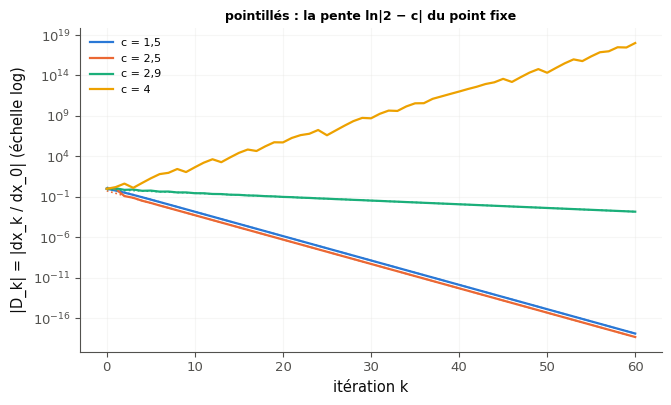

In [35]:
def iterate_with_derivative(phi, dphi, x0, n_steps):
    """The arrays (x_0, ..., x_n) and (D_0, ..., D_n), n = n_steps: x_{k+1} = phi(x_k), D_0 = 1 and
    D_{k+1} = dphi(x_k) D_k, the derivative dx_k/dx_0 by the chain rule."""
    xs, ds = [x0], [np.ones_like(x0, dtype=float)]           # x0 may be a number or an array of starts
    for _ in range(n_steps):
        ds.append(dphi(xs[-1]) * ds[-1])                     # the derivative at the point BEFORE the step
        xs.append(phi(xs[-1]))
    return np.array(xs, dtype=float), np.array(ds, dtype=float)


phi_25, dphi_25 = parabola_19(2.5)
phi_4, dphi_4 = parabola_19(4.0)
answer_M17_19a = round(dphi_25(1 - 1 / 2.5), 12)                # φ′(x*) = 2 − c
xs_25, ds_25 = iterate_with_derivative(phi_25, dphi_25, X0_19, N_STEPS_19)
answer_M17_19b = float(abs(ds_25[-1]) ** (1 / N_STEPS_19))
xs_4, ds_4 = iterate_with_derivative(phi_4, dphi_4, STARTS_19, N_STEPS_19)      # 10 000 starts at once
rates_19 = np.log(np.abs(ds_4[-1])) / N_STEPS_19
answer_M17_19c = float(np.mean(rates_19))
near_19, _ = iterate_with_derivative(phi_4, dphi_4, X0_19 + 1e-10, N_STEPS_19)
far_19, _ = iterate_with_derivative(phi_4, dphi_4, X0_19, N_STEPS_19)
answer_M17_19d = bool(abs(near_19[40] - far_19[40]) > 0.01)
uniform_19 = iterate_with_derivative(phi_4, dphi_4, np.linspace(0.01, 0.99, 10000), N_STEPS_19)[1][-1]
print("a)", answer_M17_19a, " b)", round(answer_M17_19b, 3), " c)", round(answer_M17_19c, 2),
      f"({answer_M17_19c:.4f} ; ln 2 = {math.log(2):.4f} ; écart-type des 10 000 taux : {np.std(rates_19):.3f} ; "
      f"avec 10 000 départs uniformes : {np.mean(np.log(np.abs(uniform_19))) / N_STEPS_19:.4f})",
      " d)", answer_M17_19d)
print("c = 2,5 : les premiers facteurs φ′(x_k) :", np.round(dphi_25(xs_25[:6]), 3).tolist(), "; x_60 =", xs_25[-1])
print("c = 4 : écart entre les deux trajectoires aux itérations 10, 20, 30, 40 :",
      [f"{abs(near_19[k] - far_19[k]):.1e}" for k in (10, 20, 30, 40)])

fig, ax = plt.subplots(figsize=(7.5, 4.2))
try:
    steps_19 = np.arange(N_STEPS_19 + 1)
    for c_19, colour_19 in zip(SLOPES_19, ("C0", "C1", "C2", "C3")):
        xs_19, ds_19 = (np.asarray(a, dtype=float) for a in iterate_with_derivative(*parabola_19(c_19), X0_19,
                                                                                     N_STEPS_19))
        shown_19 = f"{c_19:g}".replace(".", ",")
        ax.semilogy(steps_19, np.abs(ds_19), "-", color=colour_19, lw=1.6, label=f"c = {shown_19}")
        if c_19 < 3:                                     # the slope ln|φ_c′(x*)| = ln|2 − c|, through the last point
            ax.semilogy(steps_19, abs(ds_19[-1]) * abs(2 - c_19) ** (steps_19 - N_STEPS_19), ":", color=colour_19,
                        lw=1.2)
    ax.set_xlabel("itération k")
    ax.set_ylabel("|D_k| = |dx_k / dx_0| (échelle log)")
    ax.set_title("pointillés : la pente ln|2 − c| du point fixe", fontsize=9)
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)
except BaseException:
    plt.close(fig)
    raise
plt.show()

In [36]:
def run_19r(c, x0, n):
    """x_n and D_n for φ_c(x) = c x (1 − x), from x0 (a number or an array of starts)."""
    x, d = np.asarray(x0, dtype=float), np.ones_like(np.asarray(x0, dtype=float))
    for _ in range(n):
        x, d = c * x * (1 - x), c * (1 - 2 * x) * d
    return x, d


wbm.record("M17.19a", 2 - 2.5, decimals=4,
           mistakes={"a) demande la PENTE φ_c′(x*), pas le point fixe x* lui-même": 1 - 1 / 2.5,
                     "φ_c(x) = cx − cx² : sa dérivée est c − 2cx": 2.5 * (1 - (1 - 1 / 2.5))})
_, d_25r = run_19r(2.5, 0.3, 60)
wbm.record("M17.19b", float(abs(d_25r) ** (1 / 60)), decimals=3,
           mistakes={"b) demande |D_60|^(1/60), pas son logarithme divisé par 60": float(np.log(abs(d_25r)) / 60)})
_, d_4r = run_19r(4.0, np.sin(np.pi / 2 * np.linspace(0.0, 1.0, 10002)[1:-1]) ** 2, 60)
wbm.record("M17.19c", float(np.mean(np.log(np.abs(d_4r)) / 60)), decimals=2,
           mistakes={"le taux se calcule avec le logarithme népérien, ln": float(np.mean(np.log10(np.abs(d_4r)) / 60)),
                     "c) demande le taux (1/60) ln|D_60|, pas |D_60|^(1/60)": float(np.mean(np.abs(d_4r) ** (1 / 60)))})
wbm.record("M17.19d", bool(abs(run_19r(4.0, 0.3, 40)[0] - run_19r(4.0, 0.3 + 1e-10, 40)[0]) > 0.01),
           mistakes={"compare les deux trajectoires après 40 itérations, |x_40 − x′_40|, à 0,01 : l'écart de départ "
                     "est multiplié par |D_k| à chaque pas, en première approximation": False})

WBM_ANSWER {"coarse_any": {"1": ["121fc161daa53ebf45a8e5e5b51a10a1a63dc0edfc1c17171fc0b1ec29c55f07"]}, "coarser": {"2": ["6f84c57271a0614f8a89162e94f5225ed802905f83c014396375034b2df0741a"]}, "decimals": 4, "hash": "6e18567645f90515ea8496c9122224b502bcc33f8e1bde5b693a209d67369dbe", "hash_coarse": "0904c6b58afe2516ce5d2b6024ac20ae217d310bdb52d24d5186a0169b3dd5a5", "id": "M17.19a", "kind": "float", "magnitude": -1, "mistakes": {"86daff875a2f56fc1039b12199cd07fbda6237ac42a6ba8b546c32c864081557": "φ_c(x) = cx − cx² : sa dérivée est c − 2cx", "d7ec10e7461fd611aa72eb9b5932207e8e557beddd669ab77cbe059d14936811": "a) demande la PENTE φ_c′(x*), pas le point fixe x* lui-même"}, "sign": -1}
📝 Ex M17.19a : réponse enregistrée (float, 4 décimales).
WBM_ANSWER {"coarse_any": {"1": ["3012218dd6d62fa29ae744a74038eb2ade24171268761685feae72c6e6a04211"]}, "decimals": 3, "hash": "a848205dd17b00af4bca1d317913b6decbce0a84d081055da6c47292dad65472", "hash_coarse": "a0896fc83cf09b6308f88d1c12b15ce459de1e1e70e0a9

**Dans ta copie** : pour $c = 2{,}5$, écris les premiers facteurs $\varphi_c'(x_0)$, $\varphi_c'(x_1)$, … : pourquoi b) est-elle un peu plus petite que $\lvert 2 - c\rvert$ ? Pour $c = 2{,}9$, pourquoi la courbe met-elle plus longtemps à rejoindre sa droite, et pourquoi décroît-elle si lentement ? Pour $c = 1{,}5$ et $c = 2{,}5$, les pentes sont les mêmes : qu'est-ce qui distingue les deux trajectoires (regarde le signe des $D_k$) ? Pour $c = 4$, comment l'écart de d) grandit-il entre les itérations 10 et 40, et que dit-il de la prévision de $x_{60}$ à partir d'un $x_0$ connu à $10^{-10}$ près ?

💡 a) $\varphi_c'(x) = c(1 - 2x)$ et $x^* = 1 - \frac{1}{c}$ donnent $\varphi_c'(x^*) = c - 2c + 2 = 2 - c = -0{,}5$. b) $\lvert D_{60}\rvert^{1/60} \approx 0{,}495$, un peu sous $0{,}5$ : le deuxième facteur, $\varphi_c'(x_1)$ avec $x_1 = 0{,}525$, ne vaut que $-0{,}125$, et les premiers facteurs, loin du point fixe, pèsent sur la moyenne géométrique. Les $D_k$ changent de signe à chaque pas (pente négative) : la trajectoire tourne autour de $x^*$ ; pour $c = 1{,}5$, pente $+0{,}5$, elle s'en approche d'un seul côté. Pour $c = 2{,}9$, $\lvert 2 - c\rvert = 0{,}9$ : la convergence est lente, et $D_k$ ne perd qu'un facteur $0{,}9$ par pas. c) La moyenne des 10 000 taux vaut $\approx 0{,}693$, $\ln 2$ à quelques $10^{-4}$ près : $D_k$ double en moyenne à chaque pas. Les départs suivent la loi des points d'une longue trajectoire de $\varphi_4$ (la loi de l'arc sinus, de densité $\frac{1}{\pi\sqrt{x(1 - x)}}$) ; avec des départs uniformes, la moyenne serait un peu plus petite, $\approx 0{,}686$, car les premiers pas n'ont pas encore cette loi, et un seul départ donnerait un taux qui dépend des arrondis. d) Vrai : l'écart de $10^{-10}$ est multiplié par environ $2^k$ ($\approx 10^{12}$ après 40 pas) tant qu'il reste petit, puis il sature à la taille de $[0 ; 1]$ ; après une quarantaine de pas, connaître $x_0$ à $10^{-10}$ près ne dit plus rien de $x_k$.

### Ex M17.20 — Une grille du plan déformée par une application non linéaire, et par son approximation linéaire 🎨 ★ ⏱️ 20 min
**Objectif :** voir l'approximation linéaire d'une application du plan : l'image d'une grille par l'application et par $\mathbf{p} \mapsto \mathbf{F}(\mathbf{a}) + \mathbf{J}(\mathbf{p} - \mathbf{a})$, sur un petit et sur un grand carré.  
**Prérequis :** fiche §1 · **Parcours :** C, E

La cellule fournie donne $\mathbf{F}(x, y) = (x + 0{,}4\sin y,\ y + 0{,}4\sin x)$ (`warp_20`, qui prend un point, ou un tableau de forme $(2, k)$ de $k$ points rangés en colonnes), le point $\mathbf{a} = (1 ;\ 0{,}5)$ (`A_20`), et la jacobienne $\mathbf{J}$ de $\mathbf{F}$ en $\mathbf{a}$ (`J_20`, calculée par la `numerical_jacobian` de la référence). Écris `draw_grid_images(ax, F, a, J, half_width, n_lines)`, qui dessine dans l'axe `ax` (sans en ouvrir d'autre) :
- les $n$ lignes horizontales $y = a_y + t$ et les $n$ lignes verticales $x = a_x + t$, pour $t$ dans `np.linspace(-half_width, half_width, n_lines)`, chacune limitée au carré de demi-côté `half_width` centré en $\mathbf{a}$ ;
- l'image de chaque ligne par $\mathbf{F}$, dans une couleur, et par l'approximation linéaire $\mathbf{p} \mapsto \mathbf{F}(\mathbf{a}) + \mathbf{J}(\mathbf{p} - \mathbf{a})$, dans une autre : **une courbe** `ax.plot` par ligne et par application, d'au moins 20 points répartis sur toute la ligne ;
- une légende à deux entrées (un `label` sur une seule courbe de chaque sorte), et des axes de même échelle (`ax.set_aspect("equal")`).

Ne trace pas la grille de départ elle-même, seulement ses deux images. Pour les points d'une ligne rangés en colonnes dans un tableau `P` de forme $(2, k)$, `F(P)` donne leurs images, et `F(a)[:, None] + J @ (P - a[:, None])` celles de l'approximation linéaire.

La cellule de vérification appelle ta fonction deux fois, avec $n = 5$ lignes : sur un petit carré (`half_width = 0.2`) et sur un grand (`half_width = 1.5`). Elle vérifie que chaque courbe tracée est bien l'image d'une ligne de la grille (en remontant de chacun de ses points à son antécédent), qu'il ne manque aucune image, les couleurs et la légende, puis affiche ta figure.

In [37]:
A_20 = np.array([1.0, 0.5])            # the centre a of the square
N_LINES_20 = 5                          # n lines in each direction


def warp_20(p):
    """F(x, y) = (x + 0.4 sin y, y + 0.4 sin x), for one point (2,) or an array (2, k) of k points in columns."""
    return np.array([p[0] + 0.4 * np.sin(p[1]), p[1] + 0.4 * np.sin(p[0])])


J_20 = ref_jacobian.numerical_jacobian(warp_20, A_20)     # the Jacobian of F at a (the reference's numerical_jacobian)


def preimages_20(points, linear):
    """The points of the plane (one per row) sent onto `points` by F (linear=False), or by p ↦ F(a) + J (p − a)."""
    points = np.asarray(points, dtype=float)
    if linear:
        return A_20 + np.linalg.solve(J_20, (points - warp_20(A_20)).T).T
    p = points.copy()
    for _ in range(80):                    # p = P − 0.4 (sin y, sin x): a contraction of ratio 0.4
        p = points - 0.4 * np.sin(p[:, ::-1])
    return p


def grid_images_20(ax, half_width, n_lines):
    """{(kind, direction, k): colour} for the curves of ax that are the image of a line of the grid: kind "F" or
    "linear", direction "h" (y = a_y + t_k) or "v" (x = a_x + t_k), t_k = np.linspace(-w, w, n)[k]. A curve counts
    when it has at least 10 points, all coming from that line, and covering the whole line."""
    ts = np.linspace(-half_width, half_width, n_lines)
    tolerance = 1e-6 * max(1.0, half_width)
    found = {}
    for line in ax.lines:
        points = np.column_stack([np.asarray(line.get_xdata(), dtype=float), np.asarray(line.get_ydata(), dtype=float)])
        if len(points) < 10 or not np.all(np.isfinite(points)):
            continue
        for kind in ("F", "linear"):
            q = preimages_20(points, kind == "linear") - A_20        # the preimages, from the centre
            for direction, fixed, free in (("h", 1, 0), ("v", 0, 1)):
                k = int(np.argmin(np.abs(ts - q[0, fixed])))
                on_line = bool(np.all(np.abs(q[:, fixed] - ts[k]) < tolerance))
                covers = bool(q[:, free].min() < -0.98 * half_width and q[:, free].max() > 0.98 * half_width
                              and np.all(np.abs(q[:, free]) <= half_width + tolerance))
                if on_line and covers:
                    found[(kind, direction, k)] = mcolors.to_hex(line.get_color())
    return found

J = [[1.0, 0.351], [0.2161, 1.0]] ; det J = 0.9241
écart entre F et son approximation aux coins du grand carré : [0.551, 0.409, 0.204, 0.421]
… et aux coins du petit carré : [0.0082, 0.0077, 0.0072, 0.0078]
✅ demi-côté 0,2 : draw_grid_images dessine dans l'axe reçu
✅ demi-côté 0,2 : les 10 lignes de la grille ont leur image par F
✅ demi-côté 0,2 : les 10 lignes de la grille ont leur image par l'approximation linéaire
✅ demi-côté 0,2 : une couleur par application
✅ demi-côté 0,2 : une légende
✅ demi-côté 1,5 : draw_grid_images dessine dans l'axe reçu
✅ demi-côté 1,5 : les 10 lignes de la grille ont leur image par F
✅ demi-côté 1,5 : les 10 lignes de la grille ont leur image par l'approximation linéaire
✅ demi-côté 1,5 : une couleur par application
✅ demi-côté 1,5 : une légende


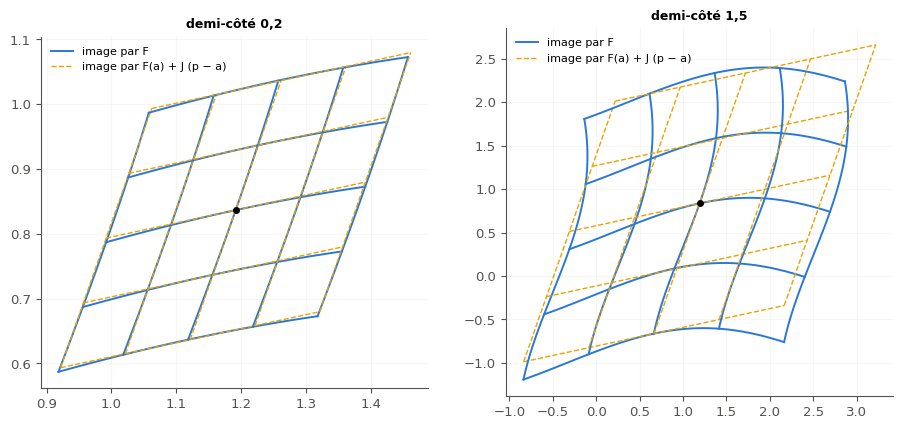

✅ Ex M17.20 : les images de la grille par F et par l'approximation linéaire sont tracées, pour les deux carrés, en deux couleurs, avec une légende.


In [38]:
def draw_grid_images(ax, F, a, J, half_width, n_lines):
    """In ax (and no other axes): the images, by F and by the linear approximation p ↦ F(a) + J (p − a), of the
    n_lines horizontal and n_lines vertical lines of the square of half side half_width centred at a; one ax.plot
    curve per line and per map (at least 20 points), one colour per map, a legend."""
    a, J = np.asarray(a, dtype=float), np.asarray(J, dtype=float)
    s = np.linspace(-half_width, half_width, 60)              # 60 points along each line
    centre = np.asarray(F(a), dtype=float)
    first = True
    for t in np.linspace(-half_width, half_width, n_lines):
        for line in (np.vstack([a[0] + s, np.full_like(s, a[1] + t)]),       # horizontal: y = a_y + t
                     np.vstack([np.full_like(s, a[0] + t), a[1] + s])):       # vertical: x = a_x + t
            exact = np.asarray(F(line), dtype=float)
            linear = centre[:, None] + J @ (line - a[:, None])
            ax.plot(exact[0], exact[1], color="C0", lw=1.4, label="image par F" if first else None)
            ax.plot(linear[0], linear[1], color="C3", lw=1.0, ls="--",
                    label="image par F(a) + J (p − a)" if first else None)
            first = False
    ax.plot([centre[0]], [centre[1]], "ko", ms=4)            # F(a), where both images touch
    ax.set_aspect("equal")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)


corners_20 = A_20 + 1.5 * np.array([[1.0, 1.0], [-1.0, 1.0], [-1.0, -1.0], [1.0, -1.0]])
gaps_20 = [np.linalg.norm(warp_20(p) - (warp_20(A_20) + J_20 @ (p - A_20))) for p in corners_20]
print("J =", np.round(J_20, 4).tolist(), "; det J =", round(float(np.linalg.det(J_20)), 4))
print("écart entre F et son approximation aux coins du grand carré :", np.round(gaps_20, 3).tolist())
small_20 = [np.linalg.norm(warp_20(p) - (warp_20(A_20) + J_20 @ (p - A_20)))
            for p in A_20 + 0.2 * np.array([[1.0, 1.0], [-1.0, 1.0], [-1.0, -1.0], [1.0, -1.0]])]
print("… et aux coins du petit carré :", np.round(small_20, 4).tolist())


with checked("M17.20"):
    results_20 = []

    def report_20(ok, success, failure):
        results_20.append(bool(ok))
        print(("✅ " + success) if ok else ("❌ " + failure))

    fig, axes = plt.subplots(1, 2, figsize=(11.0, 5.0))
    try:
        for ax, width_20 in zip(axes, (0.2, 1.5)):
            shown_20 = f"demi-côté {fr(width_20, 1)}"
            opened_20 = drawn(draw_grid_images, ax, warp_20, A_20.copy(), J_20.copy(), width_20, N_LINES_20)
            report_20(not opened_20, f"{shown_20} : draw_grid_images dessine dans l'axe reçu",
                      f"{shown_20} : draw_grid_images doit dessiner dans l'axe reçu, sans ouvrir de figure (ni "
                      f"plt.figure ni plt.subplots)")
            found_20 = grid_images_20(ax, width_20, N_LINES_20)
            for kind_20, name_20 in (("F", "par F"), ("linear", "par l'approximation linéaire")):
                missing_20 = sum((kind_20, d, k) not in found_20 for d in "hv" for k in range(N_LINES_20))
                report_20(not missing_20, f"{shown_20} : les {2 * N_LINES_20} lignes de la grille ont leur image {name_20}",
                          f"{shown_20} : il manque l'image {name_20} de {missing_20} ligne(s) de la grille sur "
                          f"{2 * N_LINES_20} (une courbe ax.plot par ligne, d'au moins 10 points, qui couvre toute la "
                          f"ligne, du bord du carré à l'autre bord)")
            colours_20 = [{c for (kind, _, _), c in found_20.items() if kind == k} for k in ("F", "linear")]
            if colours_20[0] and colours_20[1]:          # (the missing images are reported above)
                report_20(len(colours_20[0]) == 1 and len(colours_20[1]) == 1 and colours_20[0] != colours_20[1],
                          f"{shown_20} : une couleur par application",
                          f"{shown_20} : une couleur pour toutes les images par F, une autre pour toutes celles de "
                          f"l'approximation linéaire")
            entries_20 = len(ax.get_legend().get_texts()) if ax.get_legend() is not None else 0
            report_20(entries_20 >= 2, f"{shown_20} : une légende",
                      f"{shown_20} : ajoute une légende à deux entrées (label=... sur une courbe de chaque sorte, puis "
                      f"ax.legend()) : j'en compte {entries_20}")
            ax.set_title(shown_20, fontsize=9)
    except BaseException:
        plt.close(fig)
        raise
    plt.show()
    verdict("M17.20", all(results_20), "les images de la grille par F et par l'approximation linéaire sont tracées, "
                                       "pour les deux carrés, en deux couleurs, avec une légende.",
            "relis les lignes ❌ ci-dessus.")

**Regarde ta figure**, puis, dans ta copie : sur le petit carré, les deux grilles sont presque confondues ; sur le grand, elles s'écartent. Comment l'écart entre les deux images d'un coin évolue-t-il quand le demi-côté est multiplié par 7,5 (fiche §1 : de quel ordre est l'erreur de l'approximation linéaire) ? Pourquoi les images par l'approximation linéaire restent-elles des droites parallèles, et celles par $\mathbf{F}$ se courbent-elles ? Écris $\mathbf{J}$ à la main ; que vaut son déterminant, et que dit-il de l'aire de l'image d'un petit carré autour de $\mathbf{a}$ ? Les deux colonnes de $\mathbf{J}$ : où les vois-tu sur la figure ?

💡 $\mathbf{J} = \begin{pmatrix} 1 & 0{,}4\cos a_y \\ 0{,}4\cos a_x & 1 \end{pmatrix} \approx \begin{pmatrix} 1 & 0{,}351 \\ 0{,}216 & 1 \end{pmatrix}$, de déterminant $\approx 0{,}924$ : près de $\mathbf{a}$, $\mathbf{F}$ réduit les aires d'environ 8 %. L'approximation linéaire envoie la grille sur une grille de parallélogrammes, construits sur les deux colonnes de $\mathbf{J}$ (les images des pas horizontaux et verticaux) ; $\mathbf{F}$ courbe les lignes. L'erreur de l'approximation est d'ordre 2 : multiplier le demi-côté par 7,5 multiplie l'écart aux coins par un facteur de l'ordre de $7{,}5^2 \approx 56$ (de 28 à 67 selon le coin : si loin de $\mathbf{a}$, les termes d'ordre 3 comptent aussi).

## Partie C · Erreurs classiques, savoir-faire et défi

Fiche §1, §3, §4 et §5. Trois fonctions fausses à mesurer puis à corriger, un test de propriété de la règle de la chaîne, puis la jacobienne de l'inversion des matrices.

### Ex M17.21 — Chasse à l'erreur : une jacobienne transposée, un produit dans le mauvais ordre, une jacobienne évaluée au mauvais point 🐛 ★ ⏱️ 15 min
**Objectif :** reconnaître trois erreurs classiques de la règle de la chaîne qui ne lèvent aucune erreur Python (une jacobienne transposée, un produit dans le mauvais ordre, un mauvais point d'évaluation), mesurer leurs effets, puis les corriger.  
**Prérequis :** fiche §1, §3 et §4 · **Parcours :** C, E

Un collègue a écrit trois fonctions (cellule fournie) ; leurs docstrings disent ce qu'elles doivent faire, et chacune a l'erreur que nomme le titre :
- `jacobian_by_hand(p)` doit rendre la jacobienne de $\mathbf{f}(x, y) = (x^2,\ x + y)$ au point $\mathbf{p}$ ;
- `chain(Jf, Jg)` doit rendre la jacobienne de $\mathbf{g} \circ \mathbf{f}$ en $\mathbf{x}$, à partir de la jacobienne `Jf` de $\mathbf{f}$ en $\mathbf{x}$ et de la jacobienne `Jg` de $\mathbf{g}$ en $\mathbf{f}(\mathbf{x})$ ;
- `composite_jacobian(f, jac_f, jac_g, x)` doit rendre la jacobienne de $\mathbf{g} \circ \mathbf{f}$ en $\mathbf{x}$, à partir de $\mathbf{f}$ et des fonctions `jac_f` et `jac_g` qui donnent les jacobiennes de $\mathbf{f}$ et de $\mathbf{g}$ en un point.

La cellule donne aussi $\mathbf{f}$ (`f_21`), $\mathbf{g}(u, v) = (uv,\ u - v)$ (`g_21`), la jacobienne exacte de $\mathbf{g}$ (`jac_g_21`), une jacobienne numérique de $\mathbf{f}$ (`jac_f_numeric_21`, par la référence) et le point $\mathbf{x} = (1, 2)$ (`X_21`). Aucune des trois fonctions ne lève d'erreur sur ces données. Calcule à la main, puis vérifie en appelant les fonctions du collègue :
- a) ce que rend `chain(jac_f_numeric_21(X_21), jac_g_21(f_21(X_21)))` (une matrice, ses coefficients arrondis à l'entier) ;
- b) ce que rend `composite_jacobian(f_21, jac_f_numeric_21, jac_g_21, X_21)` (une matrice, arrondie à l'entier) ;
- c) la bonne jacobienne de $\mathbf{g} \circ \mathbf{f}$ en $(1, 2)$ (une matrice).

Corrige ensuite les trois fonctions : écris `jacobian_by_hand_fixed`, `chain_fixed` et `composite_jacobian_fixed`, avec les mêmes arguments et les mêmes docstrings. La vérification les essaie sur des cas que tu ne vois pas : d'autres points, d'autres applications, d'autres dimensions.

In [39]:
def f_21(p):
    """f(x, y) = (x², x + y)."""
    return np.array([p[0] ** 2, p[0] + p[1]])


def g_21(q):
    """g(u, v) = (u v, u − v)."""
    return np.array([q[0] * q[1], q[0] - q[1]])


def jac_g_21(q):
    """The Jacobian of g at q, exact (checked): one row per output."""
    return np.array([[q[1], q[0]],
                     [1.0, -1.0]])


def jac_f_numeric_21(p):
    """The Jacobian of f at p, by the reference's numerical_jacobian."""
    return ref_jacobian.numerical_jacobian(f_21, p)


X_21 = np.array([1.0, 2.0])


# The colleague's three functions
def jacobian_by_hand(p):
    """The Jacobian of f(x, y) = (x², x + y) at p = (x, y), written by hand."""
    x, y = p
    return np.array([[2 * x, 1.0],
                     [0.0, 1.0]])


def chain(Jf, Jg):
    """The Jacobian of g ∘ f at x, from the Jacobian Jf of f at x and the Jacobian Jg of g at f(x)."""
    return Jf @ Jg


def composite_jacobian(f, jac_f, jac_g, x):
    """The Jacobian of g ∘ f at x, from f and from the functions jac_f and jac_g that give the Jacobians of f and g."""
    x = np.asarray(x, dtype=float)
    return jac_g(x) @ jac_f(x)

In [40]:
jf_21 = jac_f_numeric_21(X_21)                     # J_f(1, 2)
jg_21 = jac_g_21(f_21(X_21))                       # J_g at the intermediate point f(1, 2) = (1, 3)
answer_M17_21a = np.round(chain(jf_21, jg_21)).tolist()
answer_M17_21b = np.round(composite_jacobian(f_21, jac_f_numeric_21, jac_g_21, X_21)).tolist()
answer_M17_21c = np.round(jg_21 @ jf_21).tolist()
print("J_f =", np.round(jf_21, 6).tolist(), "; jacobian_by_hand =", jacobian_by_hand(X_21).tolist())
print("a)", answer_M17_21a, " b)", answer_M17_21b, " c)", answer_M17_21c)
print("J_g au mauvais point (1, 2) :", jac_g_21(X_21).tolist())

J_f = [[2.0, 0.0], [1.0, 1.0]] ; jacobian_by_hand = [[2.0, 1.0], [0.0, 1.0]]
a) [[6.0, 2.0], [4.0, 0.0]]  b) [[5.0, 1.0], [1.0, -1.0]]  c) [[7.0, 1.0], [1.0, -1.0]]
J_g au mauvais point (1, 2) : [[2.0, 1.0], [1.0, -1.0]]


In [41]:
jf_21r = np.array([[2.0, 0.0], [1.0, 1.0]])           # J_f(1, 2)
jg_21r = np.array([[3.0, 1.0], [1.0, -1.0]])          # J_g(f(1, 2)) = J_g(1, 3)
jg_x_21r = np.array([[2.0, 1.0], [1.0, -1.0]])        # J_g(1, 2): the wrong point
wbm.record("M17.21a", (jf_21r @ jg_21r).tolist(),
           mistakes={"a) demande ce que RENVOIE chain, la fonction du collègue : refais son produit, dans son ordre":
                         (jg_21r @ jf_21r).tolist()})
wbm.record("M17.21b", (jg_x_21r @ jf_21r).tolist(),
           mistakes={"b) demande ce que RENVOIE composite_jacobian : refais son calcul, avec J_g évaluée là où elle "
                     "l'évalue": (jg_21r @ jf_21r).tolist()})
wbm.record("M17.21c", (jg_21r @ jf_21r).tolist(),
           mistakes={"la dernière application, g, a sa jacobienne à GAUCHE : J_g J_f": (jf_21r @ jg_21r).tolist(),
                     "J_g s'évalue au point intermédiaire f(1, 2), pas en (1, 2)": (jg_x_21r @ jf_21r).tolist(),
                     "la jacobienne de f a une ligne par sortie : la ligne 1 est le gradient de x²":
                         (jg_21r @ jf_21r.T).tolist()})

WBM_ANSWER {"decimals": 0, "element_hashes": ["0d812a6062b39486696b04d60ab36dd30c0f48ea8f274ed82d2492a200e7ddbe", "7caf35c7c762ac45b48be19dbfac11adcc1cba06e43579a5da6b5cc4309645e1", "07d0bd1642a52c466df20544acd3409fb1805974c4af9b063c3bb9306218cd59", "b678a95150538d4e6cb62b789a315326a17d4336b99e2a24e7de903fcbb62d69"], "hash": "8264ed002aa6a013575e0c7c1b5db60572b163fbdf5d0f28d89a561015fff420", "id": "M17.21a", "integer": true, "kind": "array", "mistakes": {"db5d95731ff7248b2c39e82935a5e8d02b1f65101579a6165d96a1b74c474042": "a) demande ce que RENVOIE chain, la fonction du collègue : refais son produit, dans son ordre"}, "shape": [2, 2]}
📝 Ex M17.21a : réponse enregistrée (array, 0 décimale).
WBM_ANSWER {"decimals": 0, "element_hashes": ["2e775a654dcbc1c621a7da7a649f788dfa2384ece30a8262a49a60a301c1404d", "b6a564665d140e38dd3d096e97c590118abafc21428b05862e252793631f0fd3", "b480eb0cd6c33868c92fb0ce8d99f9c0d6ec53154489f4fa2d07c84ad5dc8224", "36be40d2f497ae53ab944c144d2582c594a4eda45acd2f15251

**Corrige maintenant les trois fonctions.** La cellule qui suit la tienne les vérifie sur des cas que tu ne vois pas.

In [42]:
def jacobian_by_hand_fixed(p):
    """The Jacobian of f(x, y) = (x², x + y) at p = (x, y), written by hand."""
    x, y = p
    return np.array([[2 * x, 0.0],                     # row 1: the gradient of x²
                     [1.0, 1.0]])                      # row 2: the gradient of x + y


def chain_fixed(Jf, Jg):
    """The Jacobian of g ∘ f at x, from the Jacobian Jf of f at x and the Jacobian Jg of g at f(x)."""
    return np.asarray(Jg, dtype=float) @ np.asarray(Jf, dtype=float)     # the last map applied on the left


def composite_jacobian_fixed(f, jac_f, jac_g, x):
    """The Jacobian of g ∘ f at x, from f and from the functions jac_f and jac_g that give the Jacobians of f and g."""
    x = np.asarray(x, dtype=float)
    return np.asarray(jac_g(f(x)), dtype=float) @ np.asarray(jac_f(x), dtype=float)   # J_g at the point f(x)


with checked("M17.21"):
    results_21 = []

    def report_21(ok, success, failure):
        results_21.append(bool(ok))
        print(("✅ " + success) if ok else ("❌ " + failure))

    def outcome_21(call):
        """(the value of call(), "") or (None, the error it raises); NotImplementedError goes through: ⏳."""
        try:
            with warnings.catch_warnings():
                warnings.simplefilter("ignore", RuntimeWarning)
                return call(), ""
        except NotImplementedError:
            raise
        except Exception as exc:  # noqa: BLE001 - reported below
            return None, f"{type(exc).__name__} : {str(exc)[:120]}"

    def same_21(got, want):
        try:
            return got is not None and np.shape(got) == np.shape(want) and bool(np.allclose(np.asarray(got, dtype=float),
                                                                                           want))
        except (TypeError, ValueError):
            return False

    def shown_21(got, error):
        if error:
            return f"ta fonction lève {error}"
        try:
            return "reçu None" if got is None else f"reçu {np.round(np.asarray(got, dtype=float), 3).tolist()}"
        except (TypeError, ValueError):
            return f"reçu {got!r}"[:120]

    rng_21 = np.random.default_rng(5036)
    wrong_points_21 = []                                         # (A) the Jacobian of f at four other points
    for p_21 in rng_21.integers(-4, 5, size=(4, 2)).astype(float):
        want_21 = np.array([[2 * p_21[0], 0.0], [1.0, 1.0]])
        got_21, error_21 = outcome_21(lambda: jacobian_by_hand_fixed(p_21.copy()))
        if not same_21(got_21, want_21):
            wrong_points_21.append(f"en {p_21.tolist()} : attendu {want_21.tolist()}, {shown_21(got_21, error_21)}")
    report_21(not wrong_points_21, "jacobian_by_hand_fixed : la jacobienne de f en quatre autres points",
              "jacobian_by_hand_fixed, " + " ; ".join(wrong_points_21[:2]))
    for n_21, p_21, m_21 in ((2, 3, 4), (2, 2, 2), (3, 1, 2)):  # (B) f of R^n into R^p, g of R^p into R^m
        jf_21 = rng_21.integers(-3, 4, size=(p_21, n_21)).astype(float)
        jg_21 = rng_21.integers(-3, 4, size=(m_21, p_21)).astype(float)
        got_21, error_21 = outcome_21(lambda: chain_fixed(jf_21.copy(), jg_21.copy()))
        report_21(same_21(got_21, jg_21 @ jf_21), f"chain_fixed : f de R^{n_21} dans R^{p_21}, g de R^{p_21} dans R^{m_21}",
                  f"chain_fixed, f de R^{n_21} dans R^{p_21} et g de R^{p_21} dans R^{m_21} : attendu la jacobienne de "
                  f"g ∘ f, de forme ({m_21}, {n_21}) ; {shown_21(got_21, error_21)}")
    cases_21 = [                                                 # (C) label, f, jac_f, jac_g, x
        ("f de R² dans R³, g de R³ dans R²",
         lambda p: np.array([p[0] * p[1], np.sin(p[0]), p[1] ** 2]),
         lambda p: np.array([[p[1], p[0]], [np.cos(p[0]), 0.0], [0.0, 2 * p[1]]]),
         lambda q: np.array([[1.0, q[2], q[1]], [-2 * q[0], 0.0, 1.0]]),            # g(q) = (q1 + q2 q3, q3 − q1²)
         np.array([0.7, -1.3])),
        ("f et g de R² dans R²",
         lambda p: np.array([p[0] + p[1] ** 2, p[0] * p[1]]),
         lambda p: np.array([[1.0, 2 * p[1]], [p[1], p[0]]]),
         lambda q: np.array([[np.cos(q[0]), 0.0], [q[1], q[0]]]),                   # g(q) = (sin q1, q1 q2)
         np.array([0.5, -1.2])),
        ("f de R³ dans R², g de R² dans R",
         lambda p: np.array([p[0] * p[2], p[1] - p[2]]),
         lambda p: np.array([[p[2], 0.0, p[0]], [0.0, 1.0, -1.0]]),
         lambda q: np.array([[2 * q[0] * q[1], q[0] ** 2]]),                       # g(q) = q1² q2
         np.array([1.5, -0.5, 2.0])),
    ]
    for label_21, f_c21, jac_f_c21, jac_g_c21, x_c21 in cases_21:
        want_21 = jac_g_c21(f_c21(x_c21)) @ jac_f_c21(x_c21)
        got_21, error_21 = outcome_21(lambda: composite_jacobian_fixed(f_c21, jac_f_c21, jac_g_c21, x_c21.copy()))
        report_21(same_21(got_21, want_21), f"composite_jacobian_fixed : {label_21}",
                  f"composite_jacobian_fixed, {label_21} : attendu {np.round(want_21, 3).tolist()} ; "
                  f"{shown_21(got_21, error_21)}")
    verdict("M17.21", all(results_21), "les trois fonctions corrigées passent tous les cas.",
            "relis les lignes ❌ ci-dessus.")

✅ jacobian_by_hand_fixed : la jacobienne de f en quatre autres points
✅ chain_fixed : f de R^2 dans R^3, g de R^3 dans R^4
✅ chain_fixed : f de R^2 dans R^2, g de R^2 dans R^2
✅ chain_fixed : f de R^3 dans R^1, g de R^1 dans R^2
✅ composite_jacobian_fixed : f de R² dans R³, g de R³ dans R²
✅ composite_jacobian_fixed : f et g de R² dans R²
✅ composite_jacobian_fixed : f de R³ dans R², g de R² dans R
✅ Ex M17.21 : les trois fonctions corrigées passent tous les cas.


**Après la vérification**, dans ta copie : pour chaque fonction du collègue, que calcule-t-elle exactement, et quelle règle de la fiche viole-t-elle (une ligne par sortie ; la dernière application à gauche ; la jacobienne de $\mathbf{g}$ au point intermédiaire) ? En quels points `jacobian_by_hand` donnerait-elle quand même la bonne matrice ? Pour quelles applications `composite_jacobian` aurait-elle raison (pense à une $\mathbf{g}$ dont la jacobienne ne dépend pas du point) ?

💡 $\mathbf{J}_{\mathbf{f}}(1, 2) = \begin{pmatrix} 2 & 0 \\ 1 & 1 \end{pmatrix}$, $\mathbf{f}(1, 2) = (1, 3)$ et $\mathbf{J}_{\mathbf{g}}(1, 3) = \begin{pmatrix} 3 & 1 \\ 1 & -1 \end{pmatrix}$. a) `chain` rend $\mathbf{J}_{\mathbf{f}}\mathbf{J}_{\mathbf{g}} = \begin{pmatrix} 6 & 2 \\ 4 & 0 \end{pmatrix}$, le produit dans l'ordre où l'on applique les fonctions. b) `composite_jacobian` évalue $\mathbf{J}_{\mathbf{g}}$ en $(1, 2)$ : $\begin{pmatrix} 2 & 1 \\ 1 & -1 \end{pmatrix}\begin{pmatrix} 2 & 0 \\ 1 & 1 \end{pmatrix} = \begin{pmatrix} 5 & 1 \\ 1 & -1 \end{pmatrix}$. c) $\mathbf{J}_{\mathbf{g}}(1, 3)\,\mathbf{J}_{\mathbf{f}}(1, 2) = \begin{pmatrix} 7 & 1 \\ 1 & -1 \end{pmatrix}$ ; vérification directe : $\mathbf{g}(\mathbf{f}(x, y)) = (x^3 + x^2y,\ x^2 - x - y)$, de jacobienne $\begin{pmatrix} 3x^2 + 2xy & x^2 \\ 2x - 1 & -1 \end{pmatrix}$ en $(1, 2)$. `jacobian_by_hand` range une ligne par **entrée** : elle n'aurait raison que si la jacobienne était symétrique, ce qui n'arrive jamais ici (ses cases hors de la diagonale valent 0 et 1). `composite_jacobian` aurait raison si $\mathbf{J}_{\mathbf{g}}$ était la même partout, c'est-à-dire pour $\mathbf{g}$ affine, ou par chance si $\mathbf{f}(\mathbf{x})$ et $\mathbf{x}$ donnaient la même jacobienne de $\mathbf{g}$.

### Ex M17.22 — Un test de propriété : J_{g∘f} = J_g J_f sur des applications tirées au hasard 🛠️ ★ ⏱️ 15 min
**Objectif :** écrire un test de propriété de la règle de la chaîne, qui ne connaît aucune jacobienne exacte, et s'assurer qu'il attrape des implémentations fausses.  
**Prérequis :** fiche §3 ; Ex M17.14 · **Parcours :** C

Écris `test_chain_rule(jacobian)`, une fonction de test dans le style de pytest (des `assert` avec un message qui dit le cas), qui reçoit une fonction `jacobian(f, x)` de même contrat que `numerical_jacobian` (une matrice $(m, n)$, une ligne par sortie) et vérifie la règle de la chaîne du §3 :
- avec un générateur de graine 5035 (`np.random.default_rng(5035)`, créé dans le test), tire une matrice $\mathbf{A}$ de forme $(4, 3)$ et une matrice $\mathbf{B}$ de forme $(2, 4)$, de coefficients de loi normale, et définis $\mathbf{f}(\mathbf{x}) = \sin(\mathbf{A}\mathbf{x})$, de $\mathbb{R}^3$ dans $\mathbb{R}^4$, et $\mathbf{g}(\mathbf{y}) = (\mathbf{B}\mathbf{y}) \odot (\mathbf{B}\mathbf{y})$, de $\mathbb{R}^4$ dans $\mathbb{R}^2$ ;
- en **au moins 3 points** $\mathbf{x}$ tirés au hasard, calcule avec `jacobian` les trois jacobiennes $\mathbf{J}_{\mathbf{g} \circ \mathbf{f}}(\mathbf{x})$, $\mathbf{J}_{\mathbf{g}}(\mathbf{f}(\mathbf{x}))$ et $\mathbf{J}_{\mathbf{f}}(\mathbf{x})$ ;
- vérifie d'abord leurs formes, $(2, 3)$, $(2, 4)$ et $(4, 3)$, puis que $\mathbf{J}_{\mathbf{g} \circ \mathbf{f}}(\mathbf{x})$ et $\mathbf{J}_{\mathbf{g}}(\mathbf{f}(\mathbf{x}))\,\mathbf{J}_{\mathbf{f}}(\mathbf{x})$ coïncident à une tolérance de l'ordre de $10^{-6}$ (`np.allclose(..., rtol=1e-6, atol=1e-6)`).

C'est un test de **propriété** : il ne compare à aucune formule exacte de jacobienne, seulement trois jacobiennes calculées par la fonction testée.

La vérification appelle ton test sur la `numerical_jacobian` de la référence, où il doit **passer**, et compte les jacobiennes qu'il calcule ; puis sur deux implémentations fausses de la cellule fournie, où il doit **échouer** (par un `assert`, pas par une autre erreur) : `jacobian_transposed`, qui rend la transposée, et `jacobian_forward`, des différences avant avec $h = 10^{-2}$.

Dans ta copie : quel `assert` attrape chacune des deux fausses jacobiennes ? Pourquoi un test de la règle de la chaîne peut-il attraper `jacobian_forward`, alors qu'il ne connaît aucune jacobienne exacte (les erreurs de $\mathbf{J}_{\mathbf{g} \circ \mathbf{f}}$ et de $\mathbf{J}_{\mathbf{g}}\mathbf{J}_{\mathbf{f}}$ se compensent-elles) ? Une jacobienne fausse pourrait-elle passer ce test ? Pense à une fonction qui multiplie toute jacobienne par 2, ou qui rend toujours la matrice nulle de la bonne forme.

In [43]:
def jacobian_transposed(f, x, h=1e-5):
    """A wrong Jacobian: the transpose of the right one, one row per INPUT."""
    return ref_jacobian.numerical_jacobian(f, x, h).T


def jacobian_forward(f, x, h=1e-2):
    """A wrong Jacobian: forward differences (f(x + h e_j) − f(x)) / h with h = 1e-2, wrong by about h."""
    x = np.array(x, dtype=float)
    f0 = np.atleast_1d(np.asarray(f(x.copy()), dtype=float))
    columns = []
    for j in range(len(x)):
        step = np.zeros_like(x)
        step[j] = h
        columns.append((np.atleast_1d(np.asarray(f(x + step), dtype=float)) - f0) / h)
    return np.column_stack(columns)


WRONG_22 = {"jacobian_transposed (la transposée)": jacobian_transposed,
            "jacobian_forward (des différences avant, h = 10⁻²)": jacobian_forward}

In [44]:
def test_chain_rule(jacobian):
    """J_{g∘f}(x) = J_g(f(x)) J_f(x), shapes first, for f(x) = sin(A x) of R^3 into R^4 and g(y) = (B y) ⊙ (B y) of R^4
    into R^2 (A and B drawn with the seed 5035), at a few points: three Jacobians computed by `jacobian`."""
    rng = np.random.default_rng(5035)
    A, B = rng.normal(size=(4, 3)), rng.normal(size=(2, 4))

    def f(x):
        return np.sin(A @ x)

    def g(y):
        return (B @ y) * (B @ y)

    for point in range(5):
        x = rng.normal(size=3)
        J_gf = np.asarray(jacobian(lambda p: g(f(p)), x))
        J_g = np.asarray(jacobian(g, f(x)))
        J_f = np.asarray(jacobian(f, x))
        assert J_f.shape == (4, 3), f"point {point}: J_f has the shape {J_f.shape}, not (4, 3)"
        assert J_g.shape == (2, 4), f"point {point}: J_g has the shape {J_g.shape}, not (2, 4)"
        assert J_gf.shape == (2, 3), f"point {point}: J_(g∘f) has the shape {J_gf.shape}, not (2, 3)"
        gap = float(np.max(np.abs(J_gf - J_g @ J_f)))
        assert np.allclose(J_gf, J_g @ J_f, rtol=1e-6, atol=1e-6), (
            f"point {point}, x = {np.round(x, 3).tolist()}: J_(g∘f) and J_g J_f differ by up to {gap:.2e}")


for label_22s, wrong_22s in WRONG_22.items():               # which assert catches each wrong Jacobian
    try:
        test_chain_rule(wrong_22s)
        print(label_22s, ": pas attrapée")
    except AssertionError as exc:
        print(label_22s, ":", exc)


with checked("M17.22"):
    if len(inspect.signature(test_chain_rule).parameters) != 1:
        raise TypeError("ton test prend un seul argument, la jacobienne à tester : def test_chain_rule(jacobian)")
    results_22, shapes_22 = [], []

    def report_22(ok, success, failure):
        results_22.append(bool(ok))
        print(("✅ " + success) if ok else ("❌ " + failure))

    def recorded_22(f, x, h=1e-5):
        """The reference numerical_jacobian, which records the shape of each Jacobian it returns."""
        jacobian = ref_jacobian.numerical_jacobian(f, x, h)
        shapes_22.append(tuple(jacobian.shape))
        return jacobian

    try:
        test_chain_rule(recorded_22)                   # your test on a right Jacobian: ⏳ while it is not written
        why_22 = ""
    except AssertionError as exc:
        why_22 = str(exc)[:200] or "un assert sans message"
    report_22(not why_22, "ton test passe sur la bonne jacobienne numérique",
              f"ton test échoue sur la jacobienne numérique de la référence : il refuse une implémentation juste "
              f"({why_22})")
    counts_22 = {shape: shapes_22.count(shape) for shape in ((2, 3), (2, 4), (4, 3))}
    report_22(min(counts_22.values()) >= 3,
              f"ton test calcule les jacobiennes de g ∘ f, de g et de f en {min(counts_22.values())} points",
              "ton test doit calculer, en au moins 3 points et avec la fonction reçue, les trois jacobiennes : celle "
              "de g ∘ f (forme (2, 3)), celle de g en f(x) (forme (2, 4)) et celle de f (forme (4, 3)) ; j'en compte "
              + ", ".join(f"{n} de forme {s}" for s, n in counts_22.items()))
    hints_22 = {"jacobian_transposed": "vérifie d'abord, par un assert, la forme de chaque jacobienne : (4, 3) pour f, "
                                       "(2, 4) pour g, (2, 3) pour g ∘ f",
                "jacobian_forward": "compare J_{g∘f} à J_g J_f avec une tolérance de l'ordre de 10⁻⁶ "
                                    "(np.allclose(..., rtol=1e-6, atol=1e-6)) : des différences avant avec h = 10⁻² se "
                                    "trompent d'environ 10⁻²"}
    for label_22, wrong_22 in WRONG_22.items():
        try:
            test_chain_rule(wrong_22)
            report_22(False, "", f"ton test passe sur {label_22} : il ne la voit pas ; {hints_22[wrong_22.__name__]}")
        except AssertionError:
            report_22(True, f"ton test échoue sur {label_22}", "")
        except NotImplementedError:
            raise
        except Exception as exc:  # noqa: BLE001 - a crash is not a failed assert
            report_22(False, "", f"ton test plante sur {label_22} ({type(exc).__name__} : {str(exc)[:100]}) au lieu "
                                 f"d'échouer sur un assert : {hints_22[wrong_22.__name__]}")
    verdict("M17.22", all(results_22), "ton test accepte la bonne jacobienne, calcule les trois jacobiennes en "
                                       "plusieurs points et attrape les deux fausses.", "relis les lignes ❌ ci-dessus.")

jacobian_transposed (la transposée) : point 0: J_f has the shape (3, 4), not (4, 3)
jacobian_forward (des différences avant, h = 10⁻²) : point 0, x = [0.632, -0.135, -0.825]: J_(g∘f) and J_g J_f differ by up to 4.57e-02
✅ ton test passe sur la bonne jacobienne numérique
✅ ton test calcule les jacobiennes de g ∘ f, de g et de f en 5 points
✅ ton test échoue sur jacobian_transposed (la transposée)
✅ ton test échoue sur jacobian_forward (des différences avant, h = 10⁻²)
✅ Ex M17.22 : ton test accepte la bonne jacobienne, calcule les trois jacobiennes en plusieurs points et attrape les deux fausses.


💡 `jacobian_transposed` est attrapée dès le premier `assert` de forme ($\mathbf{J}_{\mathbf{f}}$ a la forme $(3, 4)$) ; sans lui, `J_g @ J_f` lèverait une erreur de forme au lieu d'échouer proprement. `jacobian_forward` passe les formes, mais ses erreurs, d'ordre $h = 10^{-2}$, ne sont pas les mêmes des deux côtés : $\mathbf{J}_{\mathbf{g} \circ \mathbf{f}}$ et $\mathbf{J}_{\mathbf{g}}\mathbf{J}_{\mathbf{f}}$ diffèrent de quelques $10^{-2}$, bien au-delà de $10^{-6}$ ; avec des différences centrées, l'écart tombe à quelques $10^{-10}$. Un test de propriété ne voit pas tout : une fonction qui rendrait toujours $2\mathbf{J}$ échouerait (le produit donne $4\mathbf{J}_{\mathbf{g}}\mathbf{J}_{\mathbf{f}}$, pas $2\,\mathbf{J}_{\mathbf{g} \circ \mathbf{f}}$), mais une fonction qui rend toujours la matrice nulle de la bonne forme passerait : d'où l'intérêt de tester aussi contre des valeurs connues (les tests de `jacobian.py` le font).

### Ex M17.23 — Défi : la jacobienne de l'inversion X ↦ X⁻¹, vue comme une application de ℝ^{n²} dans ℝ^{n²} 🏆 ★★★ ⏱️ 25 min
**Objectif :** dériver l'inversion des matrices, la voir comme une application de $\mathbb{R}^{n^2}$ dans $\mathbb{R}^{n^2}$, et trouver une formule de sa jacobienne vérifiée numériquement.  
**Prérequis :** fiche §3 et §5 ; M12c · **Parcours :** C

L'inversion $X \mapsto X^{-1}$ des matrices $n \times n$ inversibles est une application de $\mathbb{R}^{n^2}$ dans $\mathbb{R}^{n^2}$, si l'on range les $n^2$ coefficients **ligne par ligne**, comme `X.reshape(-1)` (la convention de NumPy) : la coordonnée $ni + j$ est $X[i, j]$, les indices partant de 0, et de même pour $X^{-1}$. La cellule fournie l'écrit (`inversion_23`) et donne $X_0 = \begin{pmatrix} 2 & 1 \\ 0 & 1 \end{pmatrix}$ (`X0_23`), de déterminant 2 et d'inverse $X_0^{-1} = \begin{pmatrix} 0{,}5 & -0{,}5 \\ 0 & 1 \end{pmatrix}$, et $H = \begin{pmatrix} 0 & 1 \\ 1 & 0 \end{pmatrix}$ (`H_23`). Trouve :
- a) la jacobienne $4 \times 4$ de l'inversion en $X_0$ (4 décimales) ;
- b) son déterminant (une fraction irréductible entre guillemets) ;
- c) la dérivée de l'inversion en $X_0$ dans la direction $H$, la limite de $\frac{(X_0 + tH)^{-1} - X_0^{-1}}{t}$ quand $t \to 0$ (une matrice $2 \times 2$) ;
- d) **l'objectif chiffré** : écris `inverse_jacobian(X)`, la jacobienne $(n^2, n^2)$ de l'inversion en une matrice inversible $X$ de taille $n \times n$, par une **formule** (ni différences finies ni `numerical_jacobian`). La vérification la compare à la jacobienne numérique de la référence sur trois matrices $3 \times 3$ tirées au hasard (graine 5040), décalées de $3\mathbf{I}$ pour être inversibles : le plus grand écart doit rester **sous $10^{-6}$**.

Pour a), ta `numerical_jacobian` et `inversion_23` suffisent. Pour c) et d), dérive l'égalité $X X^{-1} = \mathbf{I}$ : si $X$ bouge de $tH$, comment $X^{-1}$ doit-il bouger pour que le produit reste $\mathbf{I}$, au premier ordre en $t$ ? Puis passe d'une direction à la matrice : la colonne $nk + l$ de la jacobienne est la dérivée dans la direction $E_{kl}$, la matrice qui a un 1 en $(k, l)$ et des 0 ailleurs, aplatie comme les autres.

La cellule de vérification compare tes valeurs de a) à c), puis calcule l'écart de d) et enregistre si l'objectif est atteint.

Dans ta copie : écris ta formule de la dérivée dans une direction $H$, et vérifie c) avec elle. Pour $n = 1$, que dit-elle (la dérivée de $x \mapsto \frac{1}{x}$) ? Retrouve la colonne 1 de a) à partir d'elle, avec $H = E_{00}$. Comment b) s'exprime-t-il à partir de $\det X_0$ ? Pourquoi le déterminant d'une matrice $4 \times 4$ ne change-t-il pas quand on change le signe de tous ses coefficients ?

In [45]:
X0_23 = np.array([[2.0, 1.0],
                  [0.0, 1.0]])
H_23 = np.array([[0.0, 1.0],
                 [1.0, 0.0]])


def inversion_23(v):
    """X ↦ X⁻¹ as a map of R^(n²) into R^(n²): v is X flattened row by row (X.reshape(-1)), n = √len(v)."""
    n = math.isqrt(len(v))
    return np.linalg.inv(np.reshape(v, (n, n))).reshape(-1)

In [46]:
from fractions import Fraction


def inverse_jacobian(X):
    """The (n², n²) Jacobian at X of X ↦ X⁻¹, the matrices flattened row by row (X.reshape(-1)), by a formula:
    neither finite differences nor numerical_jacobian."""
    inverse = np.linalg.inv(np.asarray(X, dtype=float))
    return -np.kron(inverse, inverse.T)        # ∂(X⁻¹)[i, j] / ∂X[k, l] = −X⁻¹[i, k] X⁻¹[l, j]


jacobian_23 = mymath.jacobian.numerical_jacobian(inversion_23, X0_23.reshape(-1))
answer_M17_23a = np.round(jacobian_23, 4).tolist()
answer_M17_23b = str(Fraction(float(np.linalg.det(jacobian_23))).limit_denominator(1000))
inverse_23 = np.linalg.inv(X0_23)
answer_M17_23c = (-inverse_23 @ H_23 @ inverse_23).tolist()   # from X X⁻¹ = I: H X⁻¹ + X D = 0
print("a)", answer_M17_23a)
print("b)", answer_M17_23b, " c)", answer_M17_23c)
print("formule contre différences, en X0 :", f"{np.max(np.abs(inverse_jacobian(X0_23) - jacobian_23)):.1e}",
      "; J @ H aplatie :", np.round(jacobian_23 @ H_23.reshape(-1), 6).reshape(2, 2).tolist())

a) [[-0.25, 0.0, 0.25, 0.0], [0.25, -0.5, -0.25, 0.5], [0.0, 0.0, -0.5, 0.0], [0.0, 0.0, 0.5, -1.0]]
b) 1/16  c) [[0.25, -0.75], [-0.5, 0.5]]
formule contre différences, en X0 : 1.0e-10 ; J @ H aplatie : [[0.25, -0.75], [-0.5, 0.5]]


In [47]:
inverse_23r = np.array([[0.5, -0.5], [0.0, 1.0]])           # X0⁻¹
h_23r = np.array([[0.0, 1.0], [1.0, 0.0]])
jacobian_23r = -np.kron(inverse_23r, inverse_23r.T)
wbm.record("M17.23a", jacobian_23r.tolist(), decimals=4,
           mistakes={"lignes et colonnes échangées : la ligne 2i + j est le gradient de la sortie X⁻¹[i, j], la "
                     "colonne 2k + l la dérivée par rapport à X[k, l]": jacobian_23r.T.tolist(),
                     "l'aplatissement est ligne par ligne : la coordonnée 2i + j est X[i, j], pas X[j, i]":
                         (-np.kron(inverse_23r, inverse_23r)).tolist()})
wbm.record("M17.23b", "1/16", kind="fraction", simplified=True,
           mistakes={"(−1)⁴ = 1 : changer le signe des 16 coefficients d'une matrice 4 × 4 ne change pas son "
                     "déterminant": "-1/16",
                     "c'est l'inverse de la bonne valeur : près de X₀, l'inversion fait intervenir X₀⁻¹, pas X₀": "16",
                     "c'est le déterminant de X₀⁻¹ : b) demande celui de la jacobienne 4 × 4 de a)": "1/2"})
wbm.record("M17.23c", (-inverse_23r @ h_23r @ inverse_23r).tolist(), decimals=4,
           mistakes={"un produit de matrices ne commute pas : en dérivant X X⁻¹ = I, H reste ENTRE les deux facteurs":
                         (-inverse_23r @ inverse_23r @ h_23r).tolist(),
                     "un produit de matrices ne commute pas : H reste entre les deux facteurs, ni à gauche ni à droite":
                         (-h_23r @ inverse_23r @ inverse_23r).tolist()})
wbm.record("M17.23d", True,
           mistakes={"ta formule s'écarte de la jacobienne numérique : dérive X X⁻¹ = I dans la direction E_kl, puis "
                     "range les dérivées une ligne par coefficient de X⁻¹ et une colonne par coefficient de X": False})

WBM_ANSWER {"decimals": 4, "element_coarse": [["3e14347ecca09f57498fc0100904aae4702fc9a3a45dca9bb572e373ef2e82d6"], ["ff5fd26000ac00839ad80670aeca66463f0936beba048ae0469dfbc26acfe315"], ["78365d596c55e9a0072e0570858b76d186bbeeac30ea834b3aa247eb148d4d09"], ["5438362657673338b42652b022d1777e84bed22df43cf05d725e24752078d133"], ["b48c5ee6cbf7288b836abe997366d5fbb0da1701f18c97f25c277e713183e01c"], ["f903eb7662282f21af0bb7ac170dd6aa4e08f35a2a976419ce29f00fceb43895"], ["0d99db01535e8aa1ebd35935c6225e48f45f42d2199a689b35a8a5efdf788560"], ["705dcf2fbeafd47ef22151c2e3d2c90a324bd60779d4b7e12d0da0cabc04bdf0"], ["0abfed5a49b79e82be410f27719a5a5e22186c77c32e0cee8366bb5b6c0b8795"], ["47e13b19e4b7b4843ae550239358ee121aca2676399e487eed633a7dcb762037"], ["6fc51d931ff92cd9e18774943cb35b069d6f86710cfc7b44a80a24ef8af27f4e"], ["b3b7c3db573860ad53dc8fb9e252acf760387e8bce8eebd3691abd14e313b4ae"], ["135140643ba069839ec27e64bc55dd7ba7704b9e300283ad73dab71fbedef984"], ["a19982bc3b17f0f3ebcf813b59f9b190cb85e19ea0

In [48]:
with checked("M17.23d"):
    rng_23 = np.random.default_rng(5040)
    gaps_23 = []
    for draw_23 in range(3):                           # three 3 × 3 matrices, moved by 3 I to be invertible
        X_23 = rng_23.normal(size=(3, 3)) + 3 * np.eye(3)
        want_23 = ref_jacobian.numerical_jacobian(inversion_23, X_23.reshape(-1))
        got_23 = inverse_jacobian(X_23.copy())
        if got_23 is None or np.shape(got_23) != (9, 9):
            print(f"❌ Ex M17.23 : pour une matrice 3 × 3, la jacobienne de l'inversion a la forme (9, 9) ; "
                  f"inverse_jacobian rend {'None' if got_23 is None else 'la forme ' + str(np.shape(got_23))}")
            raise StopCheck
        gaps_23.append(float(np.max(np.abs(np.asarray(got_23, dtype=float) - want_23))))
    print(f"plus grand écart avec la jacobienne numérique, sur les trois matrices : {max(gaps_23):.1e} "
          f"(objectif : moins de 1e-6)")
    wbm.check("M17.23d", bool(max(gaps_23) < 1e-6), computed=True)

plus grand écart avec la jacobienne numérique, sur les trois matrices : 5.5e-12 (objectif : moins de 1e-6)
✅ Ex M17.23d : C'est ça !


💡 En dérivant $XX^{-1} = \mathbf{I}$ dans la direction $H$ : $HX^{-1} + X\,D = 0$, donc la dérivée de l'inversion dans la direction $H$ est $D = -X^{-1}HX^{-1}$ (pour $n = 1$, $-\frac{h}{x^2}$, la dérivée de $\frac{1}{x}$). Coefficient par coefficient, $\frac{\partial(X^{-1})_{ij}}{\partial X_{kl}} = -(X^{-1})_{ik}(X^{-1})_{lj}$ : dans l'aplatissement par lignes, la jacobienne est $-(X^{-1} \otimes X^{-\top})$ (`-np.kron(inv, inv.T)`). a) $\begin{pmatrix} -0{,}25 & 0 & 0{,}25 & 0 \\ 0{,}25 & -0{,}5 & -0{,}25 & 0{,}5 \\ 0 & 0 & -0{,}5 & 0 \\ 0 & 0 & 0{,}5 & -1 \end{pmatrix}$. b) $\det(A \otimes B) = \det(A)^n\det(B)^n$ pour $A$, $B$ de taille $n$, et le signe disparaît en dimension 4 : $\det\mathbf{J} = \det(X_0^{-1})^4 = \frac{1}{16}$. c) $-X_0^{-1}HX_0^{-1} = \begin{pmatrix} 0{,}25 & -0{,}75 \\ -0{,}5 & 0{,}5 \end{pmatrix}$, aussi $\mathbf{J}$ fois $H$ aplatie. d) La formule et la jacobienne numérique coïncident à quelques $10^{-12}$ près.

## ✅ Bilan

**Auto-évaluation** (note-toi de 0 à 3 dans `mon_travail/suivi/auto_evaluation.md`) :
1. Sais-tu calculer la jacobienne d'une application de $\mathbb{R}^n$ dans $\mathbb{R}^m$, une ligne par sortie, et t'en servir comme approximation linéaire ?
2. Sais-tu reconnaître une jacobienne diagonale, et la calculer avec deux évaluations ?
3. Sais-tu dériver une composée par le produit des jacobiennes, dans le bon ordre et au bon point ?
4. Sais-tu passer du gradient en ligne au gradient de la forme de la variable, et calculer un produit jacobienne-vecteur sans former la matrice ?
5. Sais-tu dériver une fonction définie par morceaux de chaque côté d'un coin, suivre la dérivée d'une longue itération, et calculer une loi de Boltzmann ?

**La suite** : le chapitre 17 de workbookIA, qui se sert de ces outils, puis M18 (différentiation automatique et calcul matriciel), juste avant le chapitre 18 de workbookIA.